# Long-period transient search (first look at the outputs)

This notebook goes through the outputs of the transient search for one sidereal
day.  The search runs on the CHIME cosmology data (the rev_09 daily timestreams).
For each day the pipeline:

1. beamforms the visibilities in the north-south direction, which gives "hybrid"
   visibilities as a function of telescope-y (see below), east-west baseline,
   and time;
2. removes the foregrounds with a high-pass filter along RA (an m-mode filter);
3. runs a matched filter for transients over start time and east-west position
   in the beam, adding up the frequencies in 6 MHz bands, and then over all
   bands and over sub-bands;
4. keeps the best position in the beam at every telescope-y and start time.

For now we only search for transients that last a single sample (~10 s) and
have a flat spectrum.  A bright pulse that lasts longer still shows up in
several neighbouring samples.

### Why 6 MHz bands

The data have 1024 frequency channels of 0.39 MHz.  The matched filter output
for every channel, telescope-y, start time and position in the beam would be far
too large to keep, so the pipeline adds the channels up into 67 bands of 6 MHz,
which makes it about 15 times smaller and still leaves enough bands to see how a
signal depends on frequency.  The band edges follow the 6 MHz grid of the North
American television channels.  TV stations, and many other transmitters with
fixed allocations, fill one or a few of these channels, so most RFI is confined
to a few bands.  An astrophysical transient is broadband and should show up in
all of them.  Everything below is either all bands added together, groups of
bands (sub-bands), or single bands.

We processed four days on which CHIME/Pulsar detected the long-period transient
CHIME J1634+44, each with and without the RFI masks from the daily pipeline.  The
idea is to use J1634+44 as a known signal, and to understand what else shows up
in the maps.

The notebook only needs the small output files (about 1.3 GB per day for each
mask; see "Where the files are" below for how to download them), so it should
run on a laptop.

## Telescope coordinates

We describe directions on the sky by the telescope coordinates x and y.  These
are direction cosines: x is the component of the unit vector towards a source in
the east-west direction (across the cylinders, positive to the east) and y the
component in the north-south direction (along the cylinders, positive to the
north).  Overhead is x = y = 0, and the horizon is x^2 + y^2 = 1.  For a source
at hour angle h and declination dec, at the latitude of CHIME (lat),

`x = -cos(dec) sin(h)`,  `y = cos(lat) sin(dec) - sin(lat) cos(dec) cos(h)`

so on the meridian (h = 0) a source is at x = 0 and y = sin(dec - lat).  As the
sky rotates a source drifts through the beam in x, while its y hardly changes
near transit.  The CHIME 21 cm detection paper (arXiv:2202.01242) describes
these coordinates in more detail.

The north-south beamforming makes rows of constant telescope-y, and the matched
filter searches over telescope-x within each row.  In the containers the
telescope-y axis is called `el`.  It is not an elevation, and it is not clear
where the name came from, so in this notebook we call it telescope-y.

## Settings

Change `LSD` to look at a different day.

In [1]:
LSD = 3035

# On fir the files are under /scratch/ssiegel/chime/lpt/lsq_mfilt.  On a laptop,
# point this at the folder you downloaded them into (see "Where the files are").
DATA_ROOT = "/scratch/ssiegel/chime/lpt/lsq_mfilt"
# Runs from before the noise option have no suffix.  Newer runs end in "_thermal"
# (thermal noise only) or "_sky" (with the noise that scales with the sky).
RUN_SUBDIR = "band_full/mask_{mask}/fir513_ew22_native"
MASKS = ["none", "full"]

# Time of the J1634+44 pulse on each day (UTC), from the CHIME/Pulsar detections.
# On a day that is not listed here, the J1634+44 section is skipped.
J1634_UTC = {
    2389: "2020-05-25 08:23:46",
    2418: "2020-06-23 06:26:15",
    2672: "2021-03-03 13:52:08",
    3035: "2022-02-28 14:04:55",
    3915: "2024-07-25 04:18:38",
}
# Approximate position of J1634+44 (degrees).  Only used to centre the search.
J1634_RA_DEC = (248.52, 44.8)

In [2]:
import os
from datetime import datetime, timezone

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from caput.astro.skyfield import skyfield_wrapper
from ch_ephem import sources
from ch_ephem.observers import chime
from IPython.display import display
from matplotlib.colors import LogNorm

from ch_pipeline.core import containers

LAT = np.radians(chime.latitude)
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)

## Where the files are

The outputs for each day are in

`DATA_ROOT/{lsd}/band_full/mask_{mask}/fir513_ew22_native/`

where `{lsd}` is the local sidereal day and `{mask}` is `none` (no RFI masks) or
`full` (the daily RFI masks applied).  The last part of the path records the
filter settings: a 513-sample FIR filter, the 22 m east-west baseline only, and
the native time samples.

All the maps are on a grid of telescope-y (one row per north-south beam) and
start time.  At each point the matched filter tries 27 east-west positions in
the beam (values of telescope-x), since a source at a given start time can be
anywhere in the beam.  The "maxx" files keep the best of these positions, which
is what you want for finding transients.  The "x0" files keep a single position,
telescope-x = 0 (on the meridian at the start time).  At a fixed position the S/N
is just the filtered data in units of the noise, so pure noise is Gaussian with
zero mean and unit variance and structure is much easier to see.

| file | container | what it is |
|---|---|---|
| file | container | size | what it is |
|---|---|---|---|
| `transient_candidates_lsd_{lsd}.h5` | `TransientCandidateMap` | 0.2 GB | The main search result.  All bands added together, at the best position in the beam.  Besides the S/N it has the flux density (Jy) and its uncertainty, and which position and trial was best. |
| `transient_band_groups_maxx_lsd_{lsd}.h5` | `TransientBandGroupMap` | 0.6 GB | The S/N with the bands added up within each sub-band (A, B, TV1, ...; see below), and over all bands, at the best position in the beam. |
| `transient_band_groups_x0_lsd_{lsd}.h5` | `TransientBandGroupMap` | 0.4 GB | As the band groups file, but at telescope-x = 0. |
| `noise_scale_lsd_{lsd}.h5` | `HybridVisNoiseScale` | 20 MB | How much noisier the filtered data are than the radiometer equation predicts, for each frequency and telescope-y. |
| `sky_noise_lsd_{lsd}.h5` | `HybridVisSkyNoise` | 0.2 MB | A fit of the extra noise that scales with the brightness of the sky (see below). |
| `transient_each_band_maxx_lsd_{lsd}.h5` | `TransientBandGroupMap` | 4 GB | The S/N in each 6 MHz band on its own, at the best position in the beam.  Optional. |
| `transient_each_band_x0_lsd_{lsd}.h5` | `TransientBandGroupMap` | 3 GB | As the single-band file, but at telescope-x = 0.  Not used here. |
| `transient_mfilt_bands_lsd_{lsd}.h5` | `TransientMatchedFilter` | 60-100 GB | Everything the matched filter computed: the amplitude and its weight in each 6 MHz band at every position in the beam.  The other maps are made from this.  Optional. |

The notebook needs only the first five files, about 1.3 GB per day for each
mask.  If the optional ones are there (on fir), it also shows spectra in 6 MHz
bands and the flux density of J1634+44 in each band; otherwise it skips them.

To work on a laptop, copy the five files for both masks of a day with (replace
`USERNAME` and the day):

```
rsync -av --prune-empty-dirs \
  --include='mask_*/' --include='mask_*/fir513_ew22_native/' \
  --include='mask_*/fir513_ew22_native/transient_candidates_lsd_*.h5' \
  --include='mask_*/fir513_ew22_native/transient_band_groups_*_lsd_*.h5' \
  --include='mask_*/fir513_ew22_native/noise_scale_lsd_*.h5' \
  --include='mask_*/fir513_ew22_native/sky_noise_lsd_*.h5' \
  --exclude='*' \
  USERNAME@fir.alliancecan.ca:/scratch/ssiegel/chime/lpt/lsq_mfilt/2418/band_full/ \
  ~/lpt_data/2418/band_full/
```

and set `DATA_ROOT = os.path.expanduser("~/lpt_data")` above.

`transient_candidates` and the `all` group of `transient_band_groups_maxx` have
the same S/N for now (we check this below), since the search only has one trial
(a single sample with a flat spectrum).  The candidate file is the output of the
search proper: it is the best over all trials, so once we add longer durations
and other spectral indices it will differ, and it has the flux density.  The
group files only have the S/N of single-sample, flat-spectrum trials.

In [3]:
run_dirs = {m: os.path.join(DATA_ROOT, str(LSD), RUN_SUBDIR.format(mask=m)) for m in MASKS}


def run_file(mask, prefix):
    return os.path.join(run_dirs[mask], f"{prefix}_lsd_{LSD}.h5")


for m in MASKS:
    print(f"mask = {m}:  {run_dirs[m]}")
    for fn in sorted(os.listdir(run_dirs[m])):
        if fn.endswith(".h5"):
            print(f"    {fn:45s} {os.path.getsize(os.path.join(run_dirs[m], fn)) / 1e9:8.3f} GB")

# The optional large files: used only if they are there
HAVE_EACH_BAND = all(os.path.exists(run_file(m, "transient_each_band_maxx")) for m in MASKS)
HAVE_MFILT_BANDS = os.path.exists(run_file("full", "transient_mfilt_bands"))
print("6 MHz band maps:", "yes" if HAVE_EACH_BAND else "no (spectra by sub-band only)")
print("per-band matched filter file:", "yes" if HAVE_MFILT_BANDS else "no")

mask = none:  /scratch/ssiegel/chime/lpt/lsq_mfilt/3035/band_full/mask_none/fir513_ew22_native
    noise_scale_lsd_3035.h5                          0.020 GB
    sky_noise_lsd_3035.h5                            0.000 GB
    transient_band_groups_maxx_lsd_3035.h5           0.634 GB
    transient_band_groups_x0_lsd_3035.h5             0.423 GB
    transient_candidates_lsd_3035.h5                 0.233 GB
    transient_each_band_maxx_lsd_3035.h5             4.241 GB
    transient_each_band_x0_lsd_3035.h5               2.828 GB
    transient_mfilt_bands_lsd_3035.h5              117.410 GB
mask = full:  /scratch/ssiegel/chime/lpt/lsq_mfilt/3035/band_full/mask_full/fir513_ew22_native
    noise_scale_lsd_3035.h5                          0.020 GB
    sky_noise_lsd_3035.h5                            0.000 GB
    transient_band_groups_maxx_lsd_3035.h5           0.634 GB
    transient_band_groups_x0_lsd_3035.h5             0.423 GB
    transient_candidates_lsd_3035.h5                 0.233 GB
    

## Containers and MPI

All the outputs are caput containers (defined in `ch_pipeline.core.containers`
and `draco.core.containers`).  A container holds datasets, the axes they are
defined on (`index_map`), and attributes.

The pipeline runs with MPI.  For these runs it used 96 processes over 4 nodes,
and a large dataset was split between them along one axis: each process only
held a block of it in memory.  In caput such a dataset is an `MPIArray`.  It
knows its global shape and which part of it this process holds, and
`.local_array` gives the part held by this process as an ordinary numpy array.
`redistribute(axis)` moves the data around so that it is split along a
different axis, which is how the pipeline gets all frequencies for a block of
telescope-y, for example.

In a notebook there is only one process, so the local part is the whole array.
It is still worth getting used to `local_array`, since the same code then works
in a pipeline task.  Loading with `distributed=True` gives `MPIArray`s, and
`distributed=False` (the default) gives plain numpy arrays.

In [4]:
cand = {
    m: containers.TransientCandidateMap.from_file(run_file(m, "transient_candidates"), distributed=True)
    for m in MASKS
}

c = cand["full"]
snr_mpi = c.snr[:]
print(type(snr_mpi).__name__, "with", c.comm.size, "process")
print("global shape:   ", snr_mpi.global_shape)
print("split along axis", snr_mpi.axis, f"({c.snr.attrs['axis'][snr_mpi.axis]})")
print("local shape:    ", snr_mpi.local_shape, " local offset:", snr_mpi.local_offset)
print("local_array is a", type(snr_mpi.local_array).__name__)

MPIArray with 1 process
global shape:    (1, 1217, 8668)
split along axis 1 (el)
local shape:     (1, 1217, 8668)  local offset: (0, np.int64(0), 0)
local_array is a ndarray


## What is in the candidate map

Every dataset has an `axis` attribute listing its axes.  The `index_map` gives
the values along each axis.

In [5]:
print("axes (index_map):")
for name, axis in c.index_map.items():
    print(f"    {name:6s} {axis.shape}  {axis.dtype}  first values: {axis[:3]}")
print("\ndatasets:")
for name, dset in c.datasets.items():
    print(f"    {name:16s} {dset.attrs['axis']}  {dset.shape}  {dset.dtype}")
print("\nattributes:")
for key in ("lsd", "tag", "ew_used", "pol_used", "duration_unit_seconds", "time_axis", "reference_freq"):
    print(f"    {key:22s} {c.attrs.get(key)}")

axes (index_map):
    el     (1217,)  float64  first values: [-1.         -0.99835526 -0.99671053]
    pol    (1,)  <U2  first values: ['co']
    ra     (8668,)  float64  first values: [0.02065135 0.06218342 0.10371549]
    x      (27,)  float64  first values: [-0.0276797  -0.02555049 -0.02342129]

datasets:
    amplitude        ['pol' 'el' 'ra']  (1, 1217, 8668)  float32
    dec              ['el' 'x']  (1217, 27)  float64
    duration         ['pol' 'el' 'ra']  (1, 1217, 8668)  int32
    ha               ['el' 'x']  (1217, 27)  float64
    snr              ['pol' 'el' 'ra']  (1, 1217, 8668)  float32
    spectral_index   ['pol' 'el' 'ra']  (1, 1217, 8668)  float32
    weight           ['pol' 'el' 'ra']  (1, 1217, 8668)  float32
    x_index          ['pol' 'el' 'ra']  (1, 1217, 8668)  int16

attributes:
    lsd                    3035
    tag                    lsd_3035
    ew_used                [22.]
    pol_used               ['XX' 'YY']
    duration_unit_seconds  9.94048024992626
 

The axes are:

- `pol`: a single entry, `co`, since XX and YY were added together.
- `el`: telescope-y (see the top of the notebook).  For a source on the
  meridian it is `sin(dec - latitude)`, so 0 is overhead and -1 and +1 are the
  southern and northern horizons.
- `ra`: the time at the **start** of the trial, as the RA of the meridian
  (degrees).  One sample is ~9.94 s.  This file only has the start times within
  the nominal sidereal day (0 to 360 degrees).
- `x`: telescope-x of the source at the start of the trial.  A source drifts in x as the sky rotates and the matched
  filter follows it.

The datasets are on `[pol, el, ra]`:

- `snr`: the best S/N over the positions in x, `amplitude * sqrt(weight)`.
- `amplitude` and `weight`: the flux density (Jy) and its inverse variance.
- `x_index`: which position in x was the best.
- `duration` (samples) and `spectral_index`: the trial, always 1 and 0 here.

and `ha` and `dec`, on `[el, x]`, give the hour angle and declination of each
position in the beam.  The RA of the source itself is `ra - ha`.

To turn an RA on this axis into a time, use `chime.lsd_to_unix(lsd + ra / 360)`.

In [6]:
el = c.index_map["el"][:]
ra = c.ra[:]
x = c.index_map["x"][:]
dra = np.median(np.diff(ra))
dt = c.attrs.get("duration_unit_seconds", 86164.0905 / 360 * dra)
ha_map = c.datasets["ha"][:]
dec_map = c.datasets["dec"][:]


def ra_to_utc(r):
    unix = chime.lsd_to_unix(LSD + r / 360.0)
    return datetime.fromtimestamp(unix, timezone.utc).strftime("%Y-%m-%d %H:%M:%S")


def utc_to_ra(utc):
    unix = datetime.strptime(utc, "%Y-%m-%d %H:%M:%S").replace(tzinfo=timezone.utc).timestamp()
    return 360.0 * (chime.unix_to_lsd(unix) - LSD)


def el_to_dec(y):
    return np.degrees(np.arcsin(np.clip(y, -1, 1)) + LAT)


def dec_to_el(d):
    return np.sin(np.radians(d) - LAT)


print(f"LSD {LSD} runs from {ra_to_utc(0)} to {ra_to_utc(360)} UTC")
print(f"{el.size} values of telescope-y, {ra.size} start times ({dt:.2f} s), {x.size} values of telescope-x")
print(f"x spans {x[0]:+.4f} to {x[-1]:+.4f}, i.e. +/-{np.degrees(np.arcsin(x[-1])):.1f} deg of hour angle on the equator")

# Plain numpy arrays for the rest of the notebook
snr = {m: cand[m].snr[:].local_array[0] for m in MASKS}
weight = {m: cand[m].weight[:].local_array[0] for m in MASKS}
best = {m: {k: cand[m].datasets[k][:].local_array[0] for k in ("amplitude", "x_index")} for m in MASKS}

LSD 3035 runs from 2022-02-27 21:28:51 to 2022-02-28 21:24:55 UTC
1217 values of telescope-y, 8668 start times (9.94 s), 27 values of telescope-x
x spans -0.0277 to +0.0277, i.e. +/-1.6 deg of hour angle on the equator


### The noise in mJy

`weight` is the inverse variance of the amplitude, so `1 / sqrt(weight)` is the
noise of a single 10 s sample in Jy, for all bands together.  It is smallest at
the centre of the beam (telescope-x = 0 and telescope-y near 0) and grows
towards the edges of the beam and the horizon, where the beam response is
weaker.  Here it is as a function of telescope-y, for samples where the best
position was the centre of the beam, and for all samples.

mask = none: noise at telescope-y = 0, beam centre: 1.50 mJy
mask = full: noise at telescope-y = 0, beam centre: 2.14 mJy


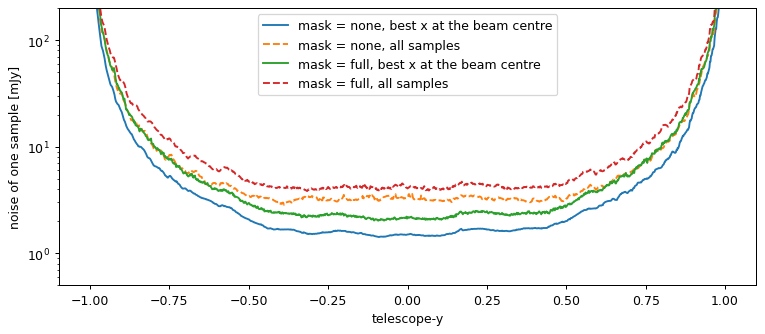

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
for m in MASKS:
    sigma = np.where(weight[m] > 0, 1 / np.sqrt(np.where(weight[m] > 0, weight[m], 1)), np.nan) * 1e3  # mJy
    centre_x = best[m]["x_index"] == x.size // 2
    med_c = [np.nanmedian(sigma[e][centre_x[e]]) if centre_x[e].any() else np.nan for e in range(el.size)]
    ax.semilogy(el, med_c, label=f"mask = {m}, best x at the beam centre")
    med_all = [np.nanmedian(row) if np.isfinite(row).any() else np.nan for row in sigma]
    ax.semilogy(el, med_all, ls="--", label=f"mask = {m}, all samples")
    i0 = np.argmin(np.abs(el))
    print(f"mask = {m}: noise at telescope-y = 0, beam centre: {med_c[i0]:.2f} mJy")
ax.set(xlabel="telescope-y", ylabel="noise of one sample [mJy]", ylim=(0.5, 200))
ax.legend()

## The noise files

The weights in the filtered data come from the radiometer equation: the noise
expected from the system temperature, the bandwidth and the integration time.
`noise_scale` is the ratio of the measured to this expected noise variance, for
each polarisation, frequency channel, east-west baseline and telescope-y,
measured from the filtered data themselves.  The matched filter divides the
weights by it, so the S/N values already include it.  A value near 1 means the
filtered data are as noisy as expected; RFI and leftover sky signal make it
larger.

noise_scale: {'el': (1217,), 'ew': (1,), 'freq': (1024,), 'pol': (2,)}
    nsample  ['pol' 'freq' 'ew' 'el']  (2, 1024, 1, 1217)
    scale    ['pol' 'freq' 'ew' 'el']  (2, 1024, 1, 1217)


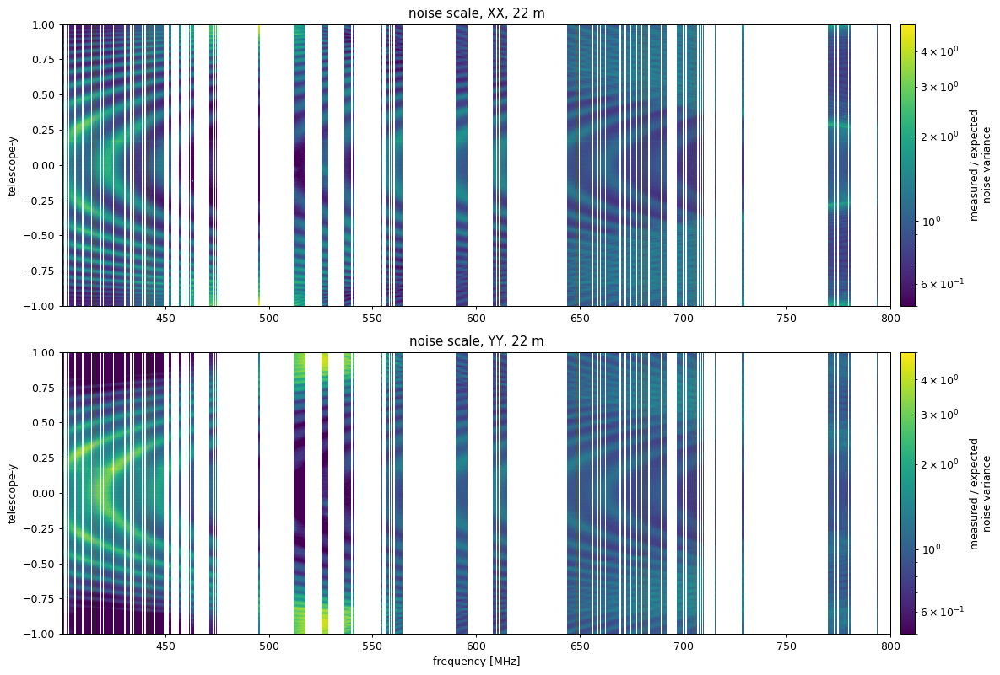

In [8]:
ns = containers.HybridVisNoiseScale.from_file(run_file("full", "noise_scale"), distributed=True)
print("noise_scale:", {k: v.shape for k, v in ns.index_map.items()})
for name, dset in ns.datasets.items():
    print(f"    {name:8s} {dset.attrs['axis']}  {dset.shape}")

# The noise changes a lot with both frequency and telescope-y, so look at all of it
fns = ns.index_map["freq"]["centre"]
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
for k, (ax, ip) in enumerate(zip(axes, range(ns.scale.shape[0]))):
    scale = ns.scale[:].local_array[ip, :, 0]  # [freq, el], 22 m
    im = ax.imshow(
        np.where(scale > 0, scale, np.nan).T, origin="lower", aspect="auto", interpolation="none",
        extent=[fns[0], fns[-1], ns.index_map["el"][0], ns.index_map["el"][-1]], norm=LogNorm(vmin=0.5, vmax=5),
    )
    ax.set(ylabel="telescope-y", title=f"noise scale, {ns.index_map['pol'][ip]}, 22 m", xlim=(fns.min(), fns.max()))
    ax.tick_params(labelbottom=True)
    plt.colorbar(im, ax=ax, pad=0.01, label="measured / expected\nnoise variance")
axes[-1].set_xlabel("frequency [MHz]")
plt.tight_layout()

## Where the bright sources are

Bright radio sources and the Sun leave residuals in the maps (more on this
below), so it helps to mark where they are.  A source transits at the RA equal
to its right ascension, at telescope-y = `sin(dec - latitude)`.  Sources that
never set (Cas A and Cyg A) also cross the meridian below the pole 12 hours
later, at telescope-y = `sin(dec + latitude)`, close to the northern horizon.
The dashed line is the Galactic plane, where it crosses the meridian.

In [9]:
SOURCES = {
    "Sun": skyfield_wrapper.ephemeris["sun"],
    "Cas A": sources.CasA,
    "Cyg A": sources.CygA,
    "Tau A": sources.TauA,
    "Vir A": sources.VirA,
    "Her A": sources.source_dictionary["HERCULES_A"],
    "Hya A": sources.source_dictionary["HYDRA_A"],
    "3C 123": sources.source_dictionary["3C_123"],
    "3C 295": sources.source_dictionary["3C_295"],
    "3C 286": sources.source_dictionary["3C_286"],
}
BELOW_POLE = ["Cas A", "Cyg A"]

marks = []  # (name, ra, el)
src_pos = {}
for name, body in SOURCES.items():
    r, d = chime.object_coords(body, chime.lsd_to_unix(LSD + 0.5), deg=True)
    r, d = chime.object_coords(body, chime.lsd_to_unix(LSD + r / 360), deg=True)
    src_pos[name] = (r % 360, d)
    marks.append((name, r % 360, dec_to_el(d)))
    if name in BELOW_POLE:
        marks.append((f"{name} (below pole)", (r + 180) % 360, np.sin(np.radians(d) + LAT)))
# Galactic centre (J2000), close to the southern horizon
marks.append(("Gal. centre", 266.40, dec_to_el(-28.94)))


def galactic_to_equatorial(l, b=0.0):
    """J2000 RA and dec (degrees) of galactic coordinates (degrees)."""
    ra_gp, dec_gp, l_ncp = np.radians([192.85948, 27.12825, 122.93192])
    l, b = np.radians(l), np.radians(b)
    sin_dec = np.sin(dec_gp) * np.sin(b) + np.cos(dec_gp) * np.cos(b) * np.cos(l_ncp - l)
    y = np.cos(b) * np.sin(l_ncp - l)
    xx = np.cos(dec_gp) * np.sin(b) - np.sin(dec_gp) * np.cos(b) * np.cos(l_ncp - l)
    return np.degrees(ra_gp + np.arctan2(y, xx)) % 360, np.degrees(np.arcsin(sin_dec))


gp_ra, gp_dec = galactic_to_equatorial(np.linspace(0, 360, 721))
order = np.argsort(gp_ra)
gp_ra, gp_el = gp_ra[order], dec_to_el(gp_dec[order])

# Expected position of the J1634+44 pulse in the map (NaN if there was no pulse
# that day, which leaves it off the maps)
HAVE_J1634 = LSD in J1634_UTC
if HAVE_J1634:
    ra_j = utc_to_ra(J1634_UTC[LSD])
    ha_j = ((ra_j - J1634_RA_DEC[0] + 180) % 360) - 180
    dec_j = np.radians(J1634_RA_DEC[1])
    el_j = np.cos(LAT) * np.sin(dec_j) - np.sin(LAT) * np.cos(dec_j) * np.cos(np.radians(ha_j))
    print(f"J1634+44 pulse at {J1634_UTC[LSD]} UTC: RA {ra_j:.2f} deg, hour angle {ha_j:+.2f} deg, telescope-y {el_j:.3f}")
else:
    ra_j = el_j = np.nan
    print(f"no CHIME/Pulsar detection of J1634+44 listed for LSD {LSD}")


def absmax_reduce(img, max_rows=600, max_cols=1600):
    """Shrink a map for display, keeping the value of largest magnitude in each block.

    A full map has ~1200 x ~8700 samples, far more than the pixels on the screen, and
    matplotlib would otherwise drop most single-sample features when it resamples.
    """
    img = np.asarray(img, dtype=np.float32)
    ke = max(1, int(np.ceil(img.shape[0] / max_rows)))
    kr = max(1, int(np.ceil(img.shape[1] / max_cols)))
    if ke == 1 and kr == 1:
        return img
    ne, nr = -(-img.shape[0] // ke) * ke, -(-img.shape[1] // kr) * kr
    pad = np.full((ne, nr), np.nan, dtype=img.dtype)
    pad[: img.shape[0], : img.shape[1]] = img
    blocks = pad.reshape(ne // ke, ke, nr // kr, kr).transpose(0, 2, 1, 3).reshape(ne // ke, nr // kr, -1)
    empty = np.all(np.isnan(blocks) | (blocks == 0), axis=-1)  # no data in the block
    blocks = np.nan_to_num(blocks)
    idx = np.argmax(np.abs(blocks), axis=-1)
    out = np.take_along_axis(blocks, idx[..., np.newaxis], axis=-1)[..., 0]
    return np.where(empty, np.nan, out)


def plot_map(ax, img, title, vmin=0, vmax=10, log=False, ra_axis=ra, el_axis=el, marks_on=True, xlabel=True,
             cmap="viridis"):
    """Image of a map on (telescope-y, ra), with the bright sources and J1634+44 marked."""
    d = np.median(np.diff(ra_axis))
    norm = LogNorm(vmin=max(vmin, 1), vmax=vmax) if log else None
    im = ax.imshow(
        absmax_reduce(img), origin="lower", aspect="auto", interpolation="none", cmap=cmap,
        extent=[ra_axis[0], ra_axis[-1] + d, el_axis[0], el_axis[-1]],
        norm=norm, vmin=None if log else vmin, vmax=None if log else vmax,
    )
    if marks_on:
        inside = (gp_ra >= ra_axis[0]) & (gp_ra <= ra_axis[-1])
        ax.plot(np.where(inside, gp_ra, np.nan), gp_el, "w--", lw=0.8, alpha=0.7)
        for name, r, y in marks + [("J1634+44", ra_j, el_j)]:
            if ra_axis[0] <= r <= ra_axis[-1] and el_axis[0] <= y <= el_axis[-1]:
                color = "r" if name == "J1634+44" else "w"
                ax.plot(r, y, "o", mfc="none", mec=color, ms=16, mew=1.5)
                # Keep the labels inside the frame
                right = r > ra_axis[0] + 0.85 * (ra_axis[-1] - ra_axis[0])
                top = y > el_axis[0] + 0.9 * (el_axis[-1] - el_axis[0])
                ax.annotate(
                    name, (r, y), xytext=(-12 if right else 12, -14 if top else 0), textcoords="offset points",
                    color=color, fontsize=11, fontweight="bold", va="top" if top else "center",
                    ha="right" if right else "left",
                )
    ax.set(ylabel="telescope-y", title=title, xlim=(ra_axis[0], ra_axis[-1] + d), ylim=(el_axis[0], el_axis[-1]))
    ax.tick_params(labelbottom=True)
    if xlabel:
        ax.set_xlabel("RA at the start [deg]")
    return im

J1634+44 pulse at 2022-02-28 14:04:55 UTC: RA 249.70 deg, hour angle +1.18 deg, telescope-y -0.079


## The noise that scales with the sky

The m-mode filter removes the steady sky, but not perfectly.  On top of the
receiver noise, the filtered data contain a residual that is a small fraction of
the unfiltered signal at the same place.  Near a bright source it can be much
larger than the receiver noise, while far from any source it is negligible.

It likely comes from the ionosphere.  Small-scale structure in the ionosphere makes
compact sources scintillate ("twinkle"), so their brightness flickers by about
0.1% from one 10 s sample to the next on a quiet night, and up to about 0.5% when
the ionosphere is active.  The m-mode filter cannot remove a change that fast, so
it ends up in the filtered data.  The flicker:

- is broadband and coherent across frequency, and larger at the bottom of the
  band (roughly as frequency to the power -1.8);
- is the same on every east-west baseline and in both polarisations, because the
  brightness of the source itself changes;
- is independent for sources in different directions;
- only affects compact sources; extended emission does not scintillate.

`sky_noise` fits this fraction from the data.  The model is that the residual
has a standard deviation of `kappa` times the unfiltered visibility.  It has two
parts: `kappa_coh` is common to all the channels of a 6 MHz band, so it does not
average down when the channels are added up, and `kappa_inc` is independent
between channels.  The coherent part is the one that matters for the search.
The fit is done for each 6 MHz band, and separately in 24 blocks of RA (the
datasets ending in `_block`; the `block` axis gives the RA at the start of each
block), so we can see how it changes through the day.

A typical value is 1-2 x 10^-3.  A 100 Jy source then leaves 0.1-0.2 Jy of noise
per 10 s sample, compared with about 2 mJy of receiver noise for all bands
together at the centre of the beam.  The runs used in this notebook do not
include this term in the matched filter, so the S/N near bright sources is too
high.  (A first-order correction, which adds it to the variance, is in the runs
ending in `_sky`; see the end of the notebook.)

sky_noise: {'block': (24,), 'ew': (1,), 'freq': (67,), 'qbin': (40,), 'source': (14,)}
datasets: ['alpha_band', 'alpha_pol', 'alpha_single', 'count', 'excess', 'kappa2_coh', 'kappa2_coh_block', 'kappa2_coh_block_weight', 'kappa2_coh_source', 'kappa2_coh_source_weight', 'kappa2_coh_weight', 'kappa2_self', 'kappa2_tot', 'kappa2_tot_block', 'kappa2_tot_block_weight', 'kappa2_tot_source', 'kappa2_tot_source_weight', 'kappa2_tot_weight', 'model', 'nsample', 'rho_pol', 'rho_pol_weight']


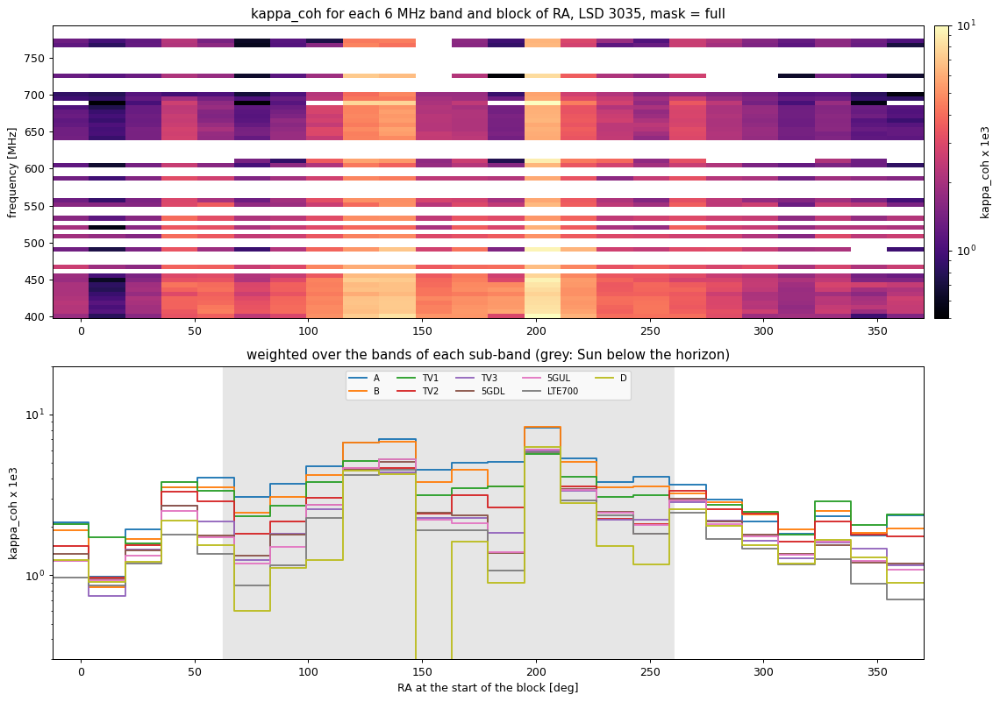

In [10]:
sky = containers.HybridVisSkyNoise.from_file(run_file("full", "sky_noise"))
print("sky_noise:", {k: v.shape for k, v in sky.index_map.items()})
print("datasets:", list(sky.datasets.keys()))

sk_centre = sky.index_map["freq"]["centre"][:]
sk_width = sky.index_map["freq"]["width"][:]
blk = np.asarray(sky.index_map["block"][:], dtype=float)
blk_edges = np.r_[blk, blk[-1] + np.median(np.diff(blk))]
k2 = sky.datasets["kappa2_coh_block"][:, 0, :]  # [band, block], 22 m
k2w = sky.datasets["kappa2_coh_block_weight"][:, 0, :]
kappa = np.where(k2w > 0, np.sqrt(np.clip(k2, 0, None)), np.nan)

# The sub-bands, from the band groups file (only the small datasets)
with h5py.File(run_file("full", "transient_band_groups_x0"), "r") as f:
    grp_names = [n.decode() if isinstance(n, bytes) else str(n) for n in f["index_map/group"][:]]
    grp_used = f["band_used"][:]

# Night: the Sun is below the horizon more than its half-day arc from transit
sun_ra, sun_dec = src_pos["Sun"]
ha_set = np.degrees(np.arccos(np.clip(-np.tan(LAT) * np.tan(np.radians(sun_dec)), -1, 1)))
rr = np.linspace(blk_edges[0], blk_edges[-1], 2000)
night = np.abs(((rr - sun_ra + 180) % 360) - 180) > ha_set

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
im = axes[0].pcolormesh(blk_edges, np.r_[sk_centre - sk_width / 2, sk_centre[-1] + sk_width[-1] / 2],
                        kappa * 1e3, norm=LogNorm(vmin=0.5, vmax=10), cmap="magma")
axes[0].set(ylabel="frequency [MHz]", title=f"kappa_coh for each 6 MHz band and block of RA, LSD {LSD}, mask = full")
axes[0].tick_params(labelbottom=True)
plt.colorbar(im, ax=axes[0], pad=0.01, label="kappa_coh x 1e3")
for name, used in zip(grp_names, grp_used):
    if name == "all":
        continue
    w = np.where(used[:, None], k2w, 0)
    kg = np.sqrt(np.clip(np.sum(w * k2, axis=0) / np.maximum(w.sum(axis=0), 1e-30), 0, None))
    kg[w.sum(axis=0) == 0] = np.nan
    axes[1].step(blk_edges, np.r_[kg, kg[-1]] * 1e3, where="post", label=name)
axes[1].fill_between(rr, 0, 1, where=night, transform=axes[1].get_xaxis_transform(), color="0.9", zorder=0)
axes[1].set(xlabel="RA at the start of the block [deg]", ylabel="kappa_coh x 1e3", yscale="log", ylim=(0.3, 20),
            title="weighted over the bands of each sub-band (grey: Sun below the horizon)")
axes[1].legend(ncol=5, fontsize=8)
plt.colorbar(im, ax=axes[1], pad=0.01).ax.set_visible(False)  # keep the two panels the same width
plt.tight_layout()

Things to notice:

- `kappa` is larger at low frequencies, as expected for ionospheric
  scintillation.
- It changes through the day, by a large factor on some days.  On some nights
  it goes up three to five times for a few hours, when the ionosphere is active.
  At those times the maps below show what we call "clouds": a dense patch of
  point-like residuals at telescope-y between about -0.75 and 0, where every
  moderately bright source leaves a residual at once.  It follows local time and
  not the sky (on LSD 2418 it starts at sunset; on LSD 3035 it is at RA 115-150
  and 180-215; LSD 1908 does not have it at all).  It is strongest south of
  zenith, where we look through more of the ionosphere.  GPS measurements of the
  ionosphere at DRAO are quiet at these times, but GPS is not sensitive to the
  small-scale structure that causes scintillation.
- Around the Sun's transit it is large too, from the Sun itself.

## The candidate maps

This is the S/N at every telescope-y and start time, without and with the RFI
masks.  It is the best of the 27 positions in x, so even pure noise gives values
around 2 and occasionally above 4; it is not a Gaussian.  The maps have far more
samples than the screen has pixels, so each pixel shows the largest value in its
block of samples (otherwise single-sample features would disappear).  First on a
log scale, to see the full range:

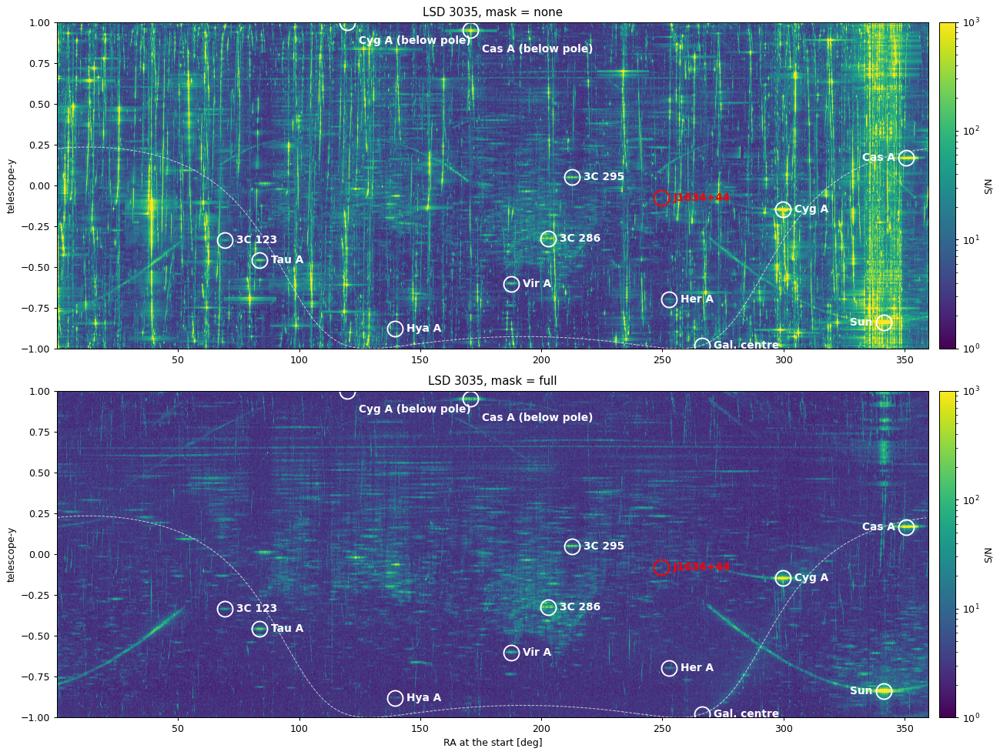

In [11]:
def two_maps(imgs, titles, **kw):
    fig, axes = plt.subplots(len(imgs), 1, figsize=(16, 5.5 * len(imgs)), sharex=True)
    axes = np.atleast_1d(axes)
    for k, (ax, img, title) in enumerate(zip(axes, imgs, titles)):
        im = plot_map(ax, img, title, xlabel=(k == len(imgs) - 1), **kw)
        plt.colorbar(im, ax=ax, pad=0.01, label="S/N")
    plt.tight_layout()


masked = {m: np.where(weight[m] > 0, snr[m], np.nan) for m in MASKS}
two_maps([masked[m] for m in MASKS], [f"LSD {LSD}, mask = {m}" for m in MASKS], vmin=1, vmax=1000, log=True)

and then on a linear scale close to the noise:

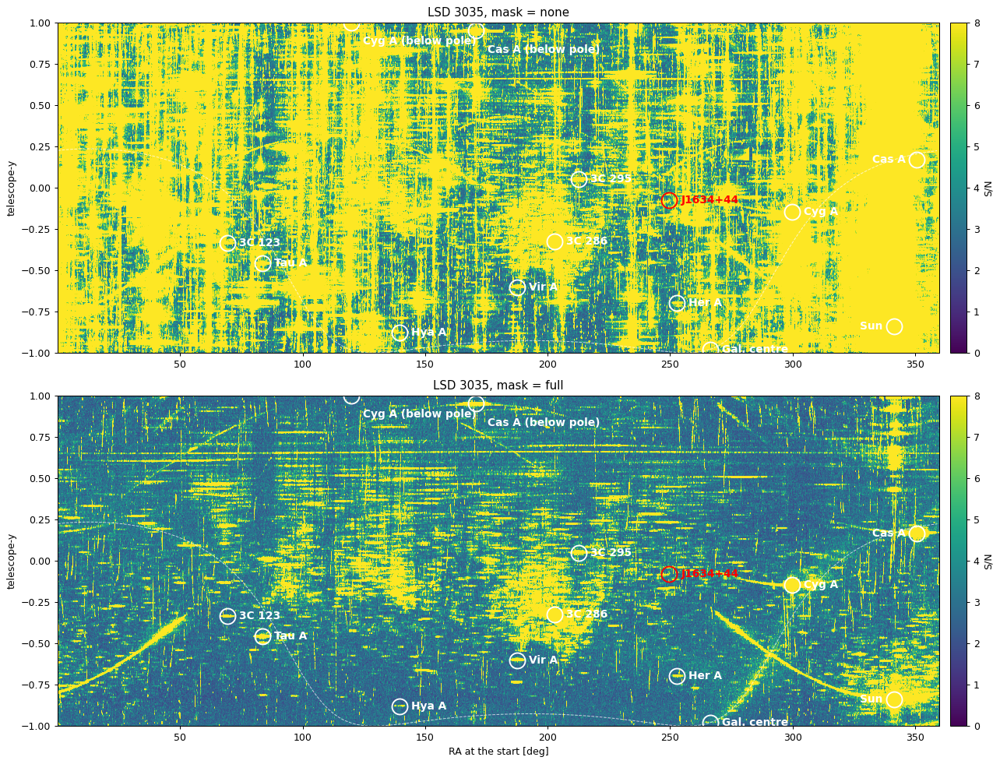

In [12]:
two_maps([masked[m] for m in MASKS], [f"LSD {LSD}, mask = {m}" for m in MASKS], vmin=0, vmax=8)

Without the masks the map is dominated by RFI.  It looks much worse than the
amount of RFI would suggest, because the filters spread each bright event out:

- Along RA: the m-mode filter subtracts a smooth fit made from the samples
  within +-256 samples (about +-43 minutes, or +-11 degrees of RA) of each
  sample.  A short, bright event pulls that fit, so a shifted copy of it is
  subtracted from its neighbours.  The copy is about 15% of the event at the
  adjacent samples, falling to a few percent by 5-10 samples away, and is small
  but not zero across the whole window.  RFI can be many orders of magnitude
  above the noise, so even that small fraction leaves a band of residuals tens of
  minutes long.
- Along telescope-y: RFI usually comes in from the horizon or through the
  sidelobes, not from one direction on the sky, so the north-south beamforming
  spreads it into many rows at once.

The masks flag the bright RFI before the filter.  The filter fits only the
unflagged samples, so the flagged events are not spread.  With the masks the
map is much better, and large parts of the sky are close to the noise.  A few
things to look for:

- Vertical lines (one start time, many values of telescope-y) are usually RFI: something
  broadband and short, coming in through the sidelobes.
- The bright sources and the Sun leave residuals at their transits, spread over
  the telescope-y near their own and along their tracks.  This is not RFI.  It
  is the noise that scales with the sky, described above.  Cas A and Cyg A
  also show up below the pole, and fainter sources (3C 286, 3C 295, ...) leave
  smaller residuals of the same kind.
- The Sun, Cyg A and Cas A are bright enough to show up along their whole
  track across the sky, through the far sidelobes of the beam, as long curves.
- On some nights there are dense patches of point-like residuals at
  southern telescope-y, at the times when `kappa` goes up (see above).  These
  come from ionospheric scintillation of the many moderately bright sources
  there, not from transients.  On LSD 2418 and 3035 they produce a large
  fraction of the candidates.
- The masks remove a lot of data (often more than half of the frequency-time
  samples), which costs sensitivity everywhere.

The distribution of S/N is a quick way to compare the two:

mask = none: valid fraction 0.998, above 8: 0.3017, above 12: 0.2108
mask = full: valid fraction 0.955, above 8: 0.0291, above 12: 0.0150


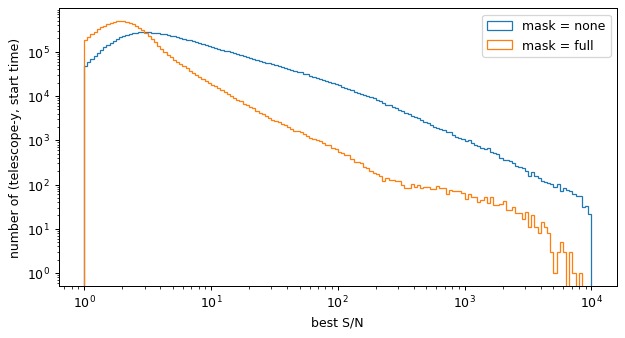

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, 4, 161)
for m in MASKS:
    ax.hist(snr[m][weight[m] > 0], bins=bins, histtype="step", label=f"mask = {m}")
ax.set(xscale="log", yscale="log", xlabel="best S/N", ylabel="number of (telescope-y, start time)")
ax.legend()
for m in MASKS:
    v = snr[m][weight[m] > 0]
    print(f"mask = {m}: valid fraction {np.mean(weight[m] > 0):.3f}, above 8: {np.mean(v > 8):.4f}, above 12: {np.mean(v > 12):.4f}")

## How it depends on frequency

The matched filter works on each 6 MHz band separately and then adds the bands
together.  The bands follow the 6 MHz grid of the North American television
channels (extended down to 398 MHz).  TV transmitters, and their reflections off
aircraft, fill a whole channel, and LTE also comes in fixed allocations, so
lining the bands up with these keeps that kind of RFI in as few bands as
possible.  An astrophysical transient is broadband: J1634+44 is seen across the
whole 400-800 MHz band.

So it is worth looking at the search in parts of the band.  Most of the RFI is
in particular places, and a real transient should show up in all of them, with
a smooth spectrum.  The sub-bands are chosen so that each allocation falls in
its own sub-band:

| sub-band | MHz | 6 MHz bands | what is there |
|---|---|---|---|
| A | 398-446 | 8 | land mobile |
| B | 446-470 | 4 | land mobile |
| TV1 | 470-518 | 8 | UHF TV channels 14-21 |
| TV2 | 518-566 | 8 | UHF TV channels 22-29 |
| TV3 | 566-614 | 8 | UHF TV channels 30-36, and 37 (radio astronomy) |
| 5GDL | 614-656 | 7 | 600 MHz 5G downlink (617-652), from about 2019 |
| 5GUL | 656-698 | 7 | 600 MHz 5G uplink (663-698) |
| LTE700 | 698-758 | 10 | 700 MHz LTE |
| D | 758-800 | 7 | public safety (758-768, 788-798) |

Above 470 MHz each 6 MHz band is exactly one TV channel, so the S/N in single
bands shows which channels have a local station and which are empty (this
needs the optional 6 MHz band files).

For a group of bands and a spectral index `alpha`, with
`s_b = (nu_b / 600 MHz)^alpha`, the S/N of the sum is

`S/N = sum(s_b w_b A_b) / sqrt(sum(s_b^2 w_b))`

where `A_b` is the amplitude in band `b` and `w_b` its inverse variance (both in
the per-band file).  This is the same sum the matched filter does over all bands.
The bands have to be added up at the same position in the beam before taking the
best one, which is why it is done in the pipeline (`CollapseBandsToGroups`).

One caveat: this assumes the noise is independent between bands.  That is true
for the thermal noise, but not for the residuals of bright sources, which are
correlated across the band, so the S/N near bright sources is too high.

In [14]:
groups = {m: containers.TransientBandGroupMap.from_file(run_file(m, "transient_band_groups_maxx"), distributed=True) for m in MASKS}

g = groups["full"]
print("groups:", [str(n) for n in g.index_map["group"]])
for name, dset in g.datasets.items():
    print(f"    {name:16s} {dset.attrs['axis']}  {dset.shape}")
centre = g.index_map["freq"]["centre"][:]
width = g.index_map["freq"]["width"][:]
group_range = {}
for k, name in enumerate(g.index_map["group"]):
    used = g.datasets["band_used"][k]
    group_range[str(name)] = ((centre - width / 2)[used].min(), (centre + width / 2)[used].max())
    print(f"    {name:8s}: {used.sum():2d} bands, {group_range[str(name)][0]:.0f}-{group_range[str(name)][1]:.0f} MHz")

# Keep the axes of the group maps (they should be the same as the candidate map)
g_el = g.index_map["el"][:]
g_ra = g.ra[:]
gsnr = {m: {name: groups[m].snr[:].local_array[0, k] for k, name in enumerate(groups[m].index_map["group"])} for m in MASKS}
gxi = {m: {name: groups[m].datasets["x_index"][:].local_array[0, k] for k, name in enumerate(groups[m].index_map["group"])}
       for m in MASKS}
g_x = g.index_map["x"][:]
g_ha = g.datasets["ha"][:]  # [el, x]
g_dec = g.datasets["dec"][:]
if HAVE_EACH_BAND:
    each = {m: containers.TransientBandGroupMap.from_file(run_file(m, "transient_each_band_maxx"), distributed=True)
            for m in MASKS}
    esnr = {m: each[m].snr[:].local_array[0] for m in MASKS}  # band, el, ra
    e_centre = each["full"].index_map["freq"]["centre"][:]
    e_width = each["full"].index_map["freq"]["width"][:]

groups: ['all', 'A', 'B', 'TV1', 'TV2', 'TV3', '5GDL', '5GUL', 'LTE700', 'D']
    band_used        ['group' 'freq']  (10, 67)
    dec              ['el' 'x']  (1217, 27)
    ha               ['el' 'x']  (1217, 27)
    snr              ['pol' 'group' 'el' 'ra']  (1, 10, 1217, 8668)
    x_index          ['pol' 'group' 'el' 'ra']  (1, 10, 1217, 8668)
    all     : 67 bands, 398-800 MHz
    A       :  8 bands, 398-446 MHz
    B       :  4 bands, 446-470 MHz
    TV1     :  8 bands, 470-518 MHz
    TV2     :  8 bands, 518-566 MHz
    TV3     :  8 bands, 566-614 MHz
    5GDL    :  7 bands, 614-656 MHz
    5GUL    :  7 bands, 656-698 MHz
    LTE700  : 10 bands, 698-758 MHz
    D       :  7 bands, 758-800 MHz


If the 6 MHz band files are there: how clean is each band?  For each 6 MHz band
on its own (best over x), this is the fraction of the map with S/N above 5.  For
pure noise it would be small and the same in every band.  The shaded ranges are
the UHF television band, the 600 MHz 5G downlink and uplink, and the 700 MHz LTE
band.

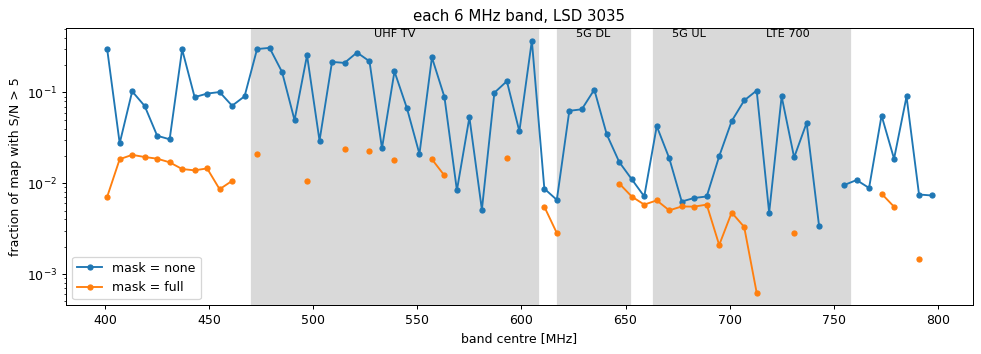

In [15]:
fig, ax = plt.subplots(figsize=(13, 4)) if HAVE_EACH_BAND else (None, None)
for m in MASKS if HAVE_EACH_BAND else []:
    has_data = esnr[m] != 0
    frac = [np.mean(esnr[m][b][has_data[b]] > 5) if has_data[b].any() else np.nan for b in range(e_centre.size)]
    ax.semilogy(e_centre, frac, "o-", ms=4, label=f"mask = {m}")
if HAVE_EACH_BAND:
    for lo, hi, label in ((470, 608, "UHF TV"), (617, 652, "5G DL"), (663, 698, "5G UL"), (698, 758, "LTE 700")):
        ax.axvspan(lo, hi, color="0.85", zorder=0)
        ax.text(0.5 * (lo + hi), 1.0, label, ha="center", va="top", fontsize=9, transform=ax.get_xaxis_transform())
    ax.set(xlabel="band centre [MHz]", ylabel="fraction of map with S/N > 5", title=f"each 6 MHz band, LSD {LSD}")
    ax.legend()
else:
    print("no 6 MHz band files; skipped")

How much of the map is above S/N 5 in each sub-band, with and without the masks.
For reference, the best of 27 positions in x of pure Gaussian noise is about 2
on average and rarely above 5.

mask = none: all 0.4508, A 0.2687, B 0.1430, TV1 0.3771, TV2 0.3043, TV3 0.2208, 5GDL 0.0323, 5GUL 0.0316, LTE700 0.0995, D 0.0702
mask = full: all 0.0660, A 0.0547, B 0.0184, TV1 0.0306, TV2 0.0286, TV3 0.0149, 5GDL 0.0107, 5GUL 0.0099, LTE700 0.0053, D 0.0075
cleanest sub-band with the masks: LTE700


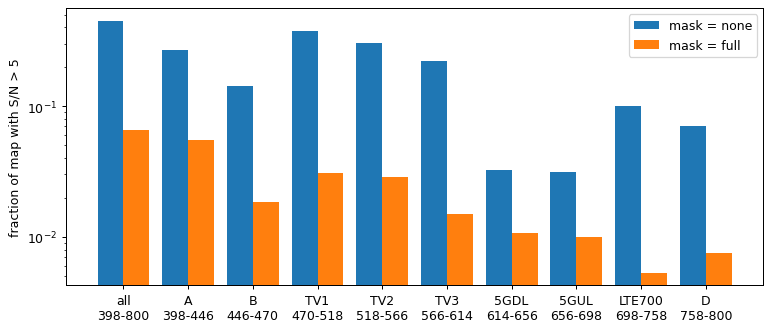

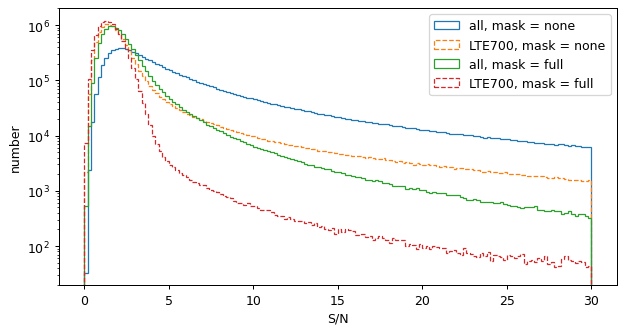

In [16]:
gnames = list(gsnr["full"])
fig, ax = plt.subplots(figsize=(10, 4))
for k, m in enumerate(MASKS):
    frac = [np.mean(gsnr[m][n][gsnr[m][n] != 0] > 5) for n in gnames]
    ax.bar(np.arange(len(gnames)) + 0.4 * (k - 0.5), frac, width=0.4, label=f"mask = {m}")
    print(f"mask = {m:4s}: " + ", ".join(f"{n} {f:.4f}" for n, f in zip(gnames, frac)))
ax.set_xticks(np.arange(len(gnames)))
ax.set_xticklabels([f"{n}\n{group_range[n][0]:.0f}-{group_range[n][1]:.0f}" for n in gnames])
ax.set(yscale="log", ylabel="fraction of map with S/N > 5")
ax.legend()

# The cleanest sub-band, with the masks
frac_full = {n: np.mean(gsnr["full"][n][gsnr["full"][n] != 0] > 5) for n in gnames if n != "all"}
clean = min(frac_full, key=frac_full.get)
print(f"cleanest sub-band with the masks: {clean}")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 30, 151)
for m in MASKS:
    for name, ls in (("all", "-"), (clean, "--")):
        v = gsnr[m][name][gsnr[m][name] != 0]
        ax.hist(v, bins=bins, histtype="step", ls=ls, label=f"{name}, mask = {m}")
ax.set(yscale="log", xlabel="S/N", ylabel="number")
ax.legend()

A check that the group files agree with the candidate map: the "all" group is
the same sum over all bands, so it should be identical.

In [17]:
ig = np.round((ra - g_ra[0]) / dra).astype(int)
has = (ig >= 0) & (ig < g_ra.size)
has[has] &= np.abs(g_ra[ig[has]] - ra[has]) < 0.5 * dra
ie = np.array([int(np.argmin(np.abs(g_el - v))) for v in el])
same_el = np.abs(g_el[ie] - el) < 1e-6
m = "full"
sel = (weight[m] > 0) & same_el[:, None] & has[None, :]
a = gsnr[m]["all"][np.ix_(ie, np.where(has, ig, 0))][sel]
b = snr[m][sel]
print(f"{sel.sum()} samples compared")
print(f"median |difference| {np.median(np.abs(a - b)):.3g}, fraction within 1%: {np.mean(np.abs(a - b) <= 1e-2 * np.abs(b) + 1e-3):.3f}")

10078425 samples compared
median |difference| 1.19e-07, fraction within 1%: 1.000


## The maps in units of the noise

The `x0` files have the S/N at a single position in the beam, telescope-x = 0,
instead of the best of all positions.  This is just the filtered data in units
of its noise, so pure noise is centred on zero with unit variance, and negative
features (for example the sidelobes of the filter around a bright residual)
show up too.  These maps are the best way to see what is going on in the data.
A source at RA r is at telescope-x = 0 at the start time r.

First, how close to Gaussian noise the maps are, for all bands and for each
sub-band:

x0 maps at telescope-x = 0.0
mask = none: robust std of the S/N (1 for pure noise): all 2.96, A 2.31, B 1.60, TV1 2.54, TV2 2.11, TV3 1.71, 5GDL 1.13, 5GUL 1.14, LTE700 1.31, D 1.26
mask = full: robust std of the S/N (1 for pure noise): all 1.31, A 1.33, B 1.13, TV1 1.15, TV2 1.14, TV3 1.07, 5GDL 1.07, 5GUL 1.08, LTE700 1.04, D 1.05


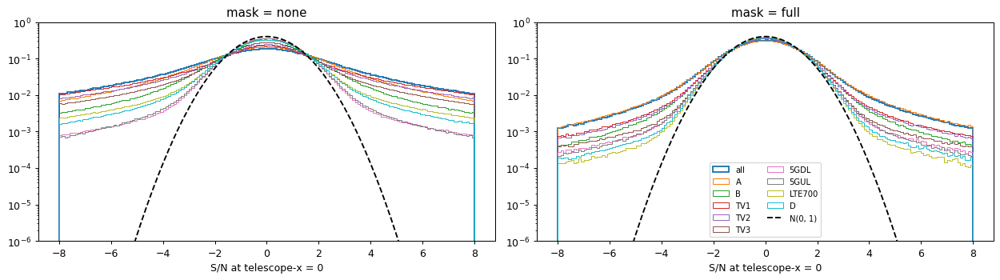

In [18]:
groups0 = {m: containers.TransientBandGroupMap.from_file(run_file(m, "transient_band_groups_x0"), distributed=True) for m in MASKS}
print("x0 maps at telescope-x =", groups0["full"].attrs["x_reduce"])

gsnr0 = {m: {str(n): groups0[m].snr[:].local_array[0, k] for k, n in enumerate(groups0[m].index_map["group"])} for m in MASKS}
g0_el = groups0["full"].index_map["el"][:]
g0_ra = groups0["full"].ra[:]

bins = np.linspace(-8, 8, 161)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for col, m in enumerate(MASKS):
    for n in gsnr0[m]:
        v = gsnr0[m][n][gsnr0[m][n] != 0]
        ax[col].hist(v, bins=bins, histtype="step", density=True, label=n, lw=1.5 if n == "all" else 0.8)
    ax[col].plot(bins, np.exp(-0.5 * bins**2) / np.sqrt(2 * np.pi), "k--", label="N(0, 1)")
    ax[col].set(yscale="log", ylim=(1e-6, 1), xlabel="S/N at telescope-x = 0", title=f"mask = {m}")
ax[1].legend(fontsize=8, ncol=2)
plt.tight_layout()

for m in MASKS:
    print(f"mask = {m}: robust std of the S/N (1 for pure noise): "
          + ", ".join(f"{n} {1.4826 * np.median(np.abs(gsnr0[m][n][gsnr0[m][n] != 0])):.2f}" for n in gsnr0[m]))

All bands, without and with the masks, on the same colour scale:

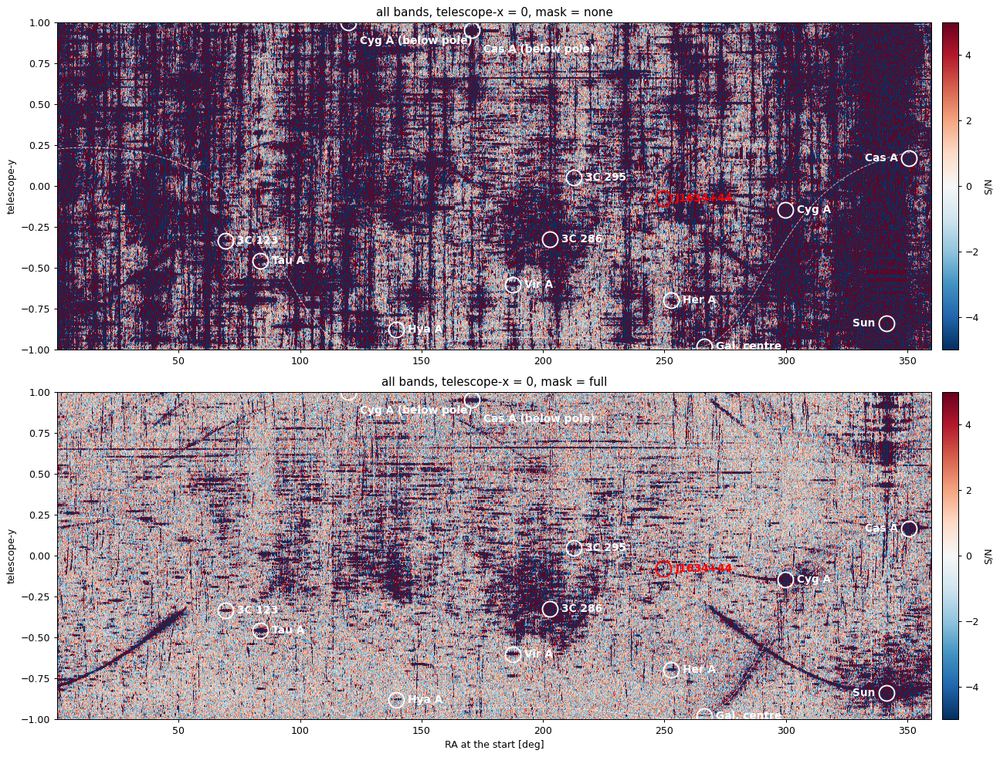

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)
for k, (ax, m) in enumerate(zip(axes, MASKS)):
    im = plot_map(ax, gsnr0[m]["all"], f"all bands, telescope-x = 0, mask = {m}", vmin=-5, vmax=5,
                  ra_axis=g0_ra, el_axis=g0_el, cmap="RdBu_r", xlabel=(k == 1))
    plt.colorbar(im, ax=ax, pad=0.01, label="S/N")
plt.tight_layout()

The maps of the separate sub-bands are most useful around a candidate, so they
are shown below for J1634+44 and for the brightest candidates rather than for
the whole day.

## J1634+44

CHIME/Pulsar gives us the time of the pulse, so we know roughly where it should
be.  We look for the brightest trial within a degree of that start time and
0.03 in telescope-y.  On a day without a detection the cells in this section do
nothing.

In [20]:
def zoom_index(e, t, half_el=40, half_ra=60, shape=None):
    n_el, n_ra = shape if shape is not None else (el.size, ra.size)
    return slice(max(e - half_el, 0), min(e + half_el + 1, n_el)), slice(max(t - half_ra, 0), min(t + half_ra + 1, n_ra))


def describe(mm, e, t):
    ix = best[mm]["x_index"][e, t]
    return (
        f"S/N {snr[mm][e, t]:6.1f}  amp {best[mm]['amplitude'][e, t]:6.2f} Jy  "
        f"y {el[e]:+.3f}  x {x[ix]:+.4f}  RA start {ra[t]:.2f}  ({ra_to_utc(ra[t])} UTC)  "
        f"src RA {(ra[t] - ha_map[e, ix]) % 360:.2f}  dec {dec_map[e, ix]:.1f}"
    )


peak = {}
if HAVE_J1634:
    near = (np.abs(el - el_j) < 0.03)[:, None] & (np.abs(ra - ra_j) < 1.0)[None, :]
    for m in MASKS:
        e, t = np.unravel_index(np.argmax(np.where(near & (weight[m] > 0), snr[m], -np.inf)), snr[m].shape)
        peak[m] = (e, t)
        print(f"mask = {m:4s}: {describe(m, e, t)}")

mask = none: S/N  199.9  amp   0.52 Jy  y -0.079  x -0.0149  RA start 249.71  (2022-02-28 14:04:58 UTC)  src RA 248.51  dec 44.8
mask = full: S/N  140.3  amp   0.48 Jy  y -0.079  x -0.0149  RA start 249.71  (2022-02-28 14:04:58 UTC)  src RA 248.51  dec 44.8


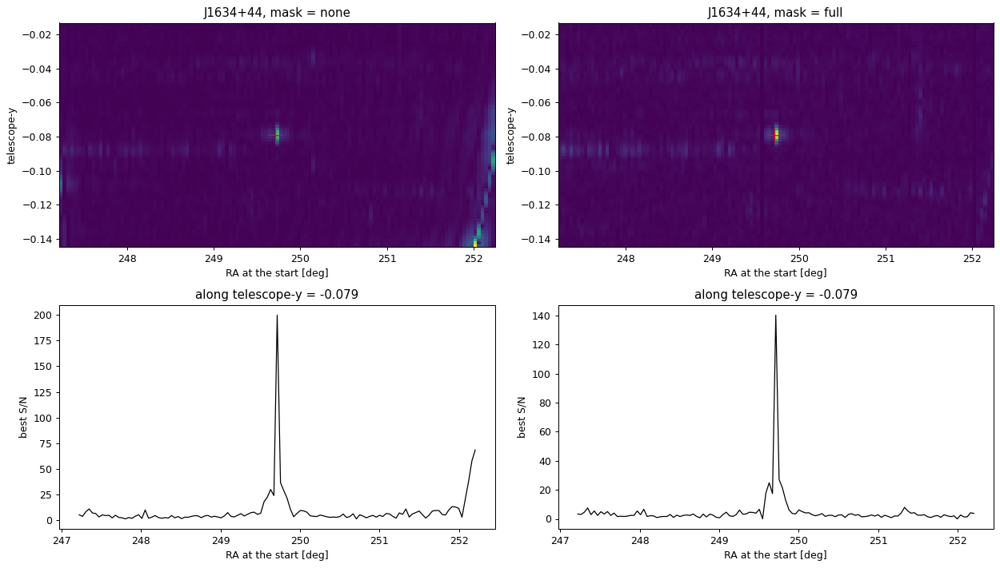

In [21]:
if HAVE_J1634:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for col, m in enumerate(MASKS):
        e, t = peak[m]
        se, st = zoom_index(e, t)
        plot_map(axes[0, col], snr[m][se, st], f"J1634+44, mask = {m}", vmax=np.nanmax(snr[m][se, st]),
                 ra_axis=ra[st], el_axis=el[se], marks_on=False)
        axes[0, col].plot(ra[t], el[e], "r+", ms=14)
        axes[1, col].plot(ra[st], snr[m][e, st], "k-", lw=1)
        axes[1, col].set(xlabel="RA at the start [deg]", ylabel="best S/N", title=f"along telescope-y = {el[e]:+.3f}")
    plt.tight_layout()

The spectrum of the pulse: the S/N in each sub-band (best over x for each
sub-band, so a bit higher than at a single x), drawn as a bar across the
sub-band with an error of 1 (the S/N is in units of the noise).  A sub-band with
more bands has more signal, so for a flat spectrum the S/N goes up with the
square root of its number of bands.  If the 6 MHz band files are there, the S/N
in each 6 MHz band is drawn too, in grey.  Below that, the map around the pulse
in all bands and in each sub-band, on the same colour scale.  The red triangles
on the frame point to the peak in the full band.

mask = none: all: 199.9, A: 135.2, B:  99.0, TV1:  76.4, TV2:  51.3, TV3:  28.4, 5GDL:  28.6, 5GUL:  46.6, LTE700:  47.1, D:  16.4
mask = full: all: 140.3, A: 102.5, B:  52.1, TV1:  47.9, TV2:  42.3, TV3:  20.0, 5GDL:  28.1, 5GUL:  42.2, LTE700:  19.6, D:  10.1


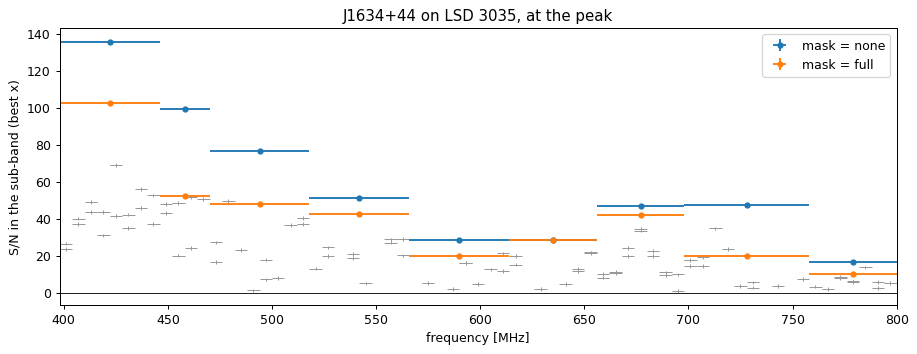

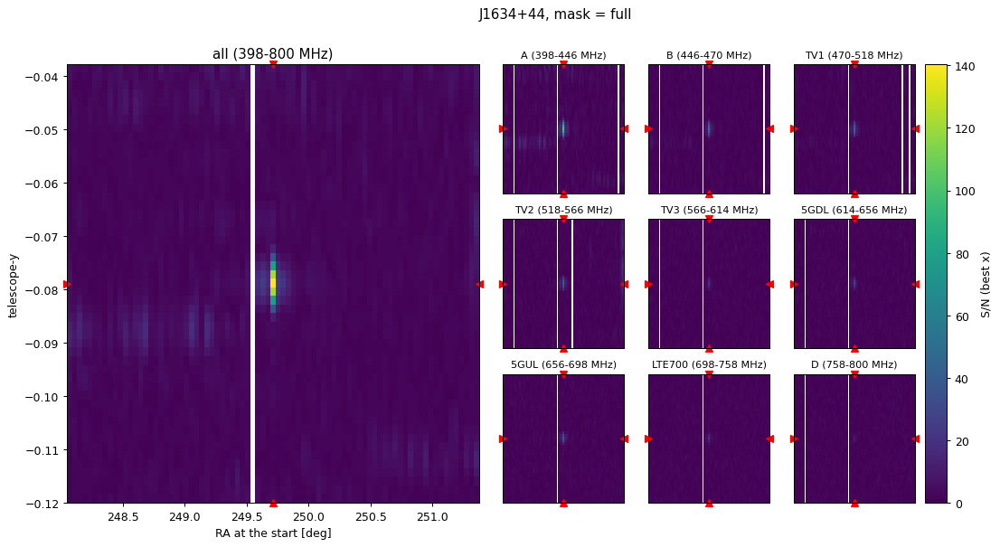

In [22]:
def at_group_pixel(e, t):
    """Indices in the group maps of a sample of the candidate map."""
    return int(np.argmin(np.abs(g_el - el[e]))), int(np.argmin(np.abs(g_ra - ra[t])))


def plot_spectrum(ax, eg, tg, mm, label=None, **kw):
    """S/N in each sub-band (and each 6 MHz band, if available) at one sample of the group maps."""
    if HAVE_EACH_BAND:
        spec = esnr[mm][:, eg, tg]
        ok = spec != 0
        ax.errorbar(e_centre[ok], spec[ok], xerr=e_width[ok] / 2, yerr=1, fmt="none", color="0.6", lw=0.8)
    subs = [n for n in gsnr[mm] if n != "all"]
    lo = np.array([group_range[n][0] for n in subs])
    hi = np.array([group_range[n][1] for n in subs])
    val = np.array([gsnr[mm][n][eg, tg] for n in subs])
    ok = val != 0
    ax.errorbar(0.5 * (lo + hi)[ok], val[ok], xerr=0.5 * (hi - lo)[ok], yerr=1, fmt="o", ms=4, label=label, **kw)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="frequency [MHz]", ylabel="S/N in the sub-band (best x)", xlim=(398, 800))


def edge_marks(ax, r, y):
    """Mark a position with small triangles outside the frame, so the source itself stays visible."""
    kw = dict(color="r", ms=7, clip_on=False, transform=ax.transData)
    y0, y1 = ax.get_ylim()
    x0, x1 = ax.get_xlim()
    ax.plot(r, y1, "v", **kw)
    ax.plot(r, y0, "^", **kw)
    ax.plot(x0, y, ">", **kw)
    ax.plot(x1, y, "<", **kw)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)


def band_panels(eg, tg, mm, title, half_el=25, half_ra=40):
    """Maps around one sample: all bands (large) and each sub-band, on one colour scale."""
    se = slice(max(eg - half_el, 0), min(eg + half_el + 1, g_el.size))
    st = slice(max(tg - half_ra, 0), min(tg + half_ra + 1, g_ra.size))
    ext = [g_ra[st][0], g_ra[st][-1], g_el[se][0], g_el[se][-1]]
    vmax = max(5.0, np.nanmax(gsnr[mm]["all"][se, st]))
    subs = [n for n in gsnr[mm] if n != "all"]

    fig = plt.figure(figsize=(16, 7))
    gs = fig.add_gridspec(3, 6)
    axes = [fig.add_subplot(gs[:, :3])] + [fig.add_subplot(gs[k // 3, 3 + k % 3]) for k in range(len(subs))]
    for k, (ax, n) in enumerate(zip(axes, ["all"] + subs)):
        lo, hi = group_range[n]
        img = gsnr[mm][n][se, st]
        im = ax.imshow(np.where(img != 0, img, np.nan), origin="lower", aspect="auto", interpolation="none",
                       extent=ext, vmin=0, vmax=vmax)
        edge_marks(ax, g_ra[tg], g_el[eg])
        ax.set_title(f"{n} ({lo:.0f}-{hi:.0f} MHz)", fontsize=12 if k == 0 else 9)
        if k == 0:
            ax.set(xlabel="RA at the start [deg]", ylabel="telescope-y")
        else:
            ax.set_xticks([])
            ax.set_yticks([])
    fig.colorbar(im, ax=axes, pad=0.01, label="S/N (best x)")
    fig.suptitle(title)


if HAVE_J1634:
    fig, ax = plt.subplots(figsize=(12, 4))
    for k, m in enumerate(MASKS):
        eg, tg = at_group_pixel(*peak[m])
        plot_spectrum(ax, eg, tg, m, color=f"C{k}", label=f"mask = {m}")
        print(f"mask = {m:4s}: " + ", ".join(f"{n}: {gsnr[m][n][eg, tg]:5.1f}" for n in gsnr[m]))
    ax.set_title(f"J1634+44 on LSD {LSD}, at the peak")
    ax.legend()
    band_panels(*at_group_pixel(*peak["full"]), "full", "J1634+44, mask = full")

If you need the amplitude in each band at one particular position in the beam,
read just that sample from the big per-band file (on fir).  Containers can load
a subset with `<axis>_sel` arguments, so this only reads a few chunks:

    amplitude  ['pol' 'duration' 'freq' 'el' 'ra' 'x']  (1, 1, 67, 1, 1, 27)
    dec        ['el' 'x']  (1, 27)
    ha         ['el' 'x']  (1, 27)
    weight     ['pol' 'duration' 'freq' 'el' 'ra' 'x']  (1, 1, 67, 1, 1, 27)


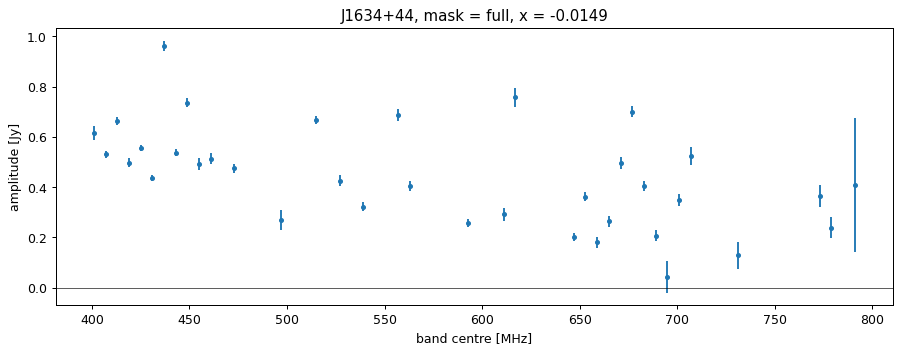

In [23]:
m = "full"
bands_file = run_file(m, "transient_mfilt_bands")
if HAVE_J1634 and not HAVE_MFILT_BANDS:
    print("no per-band matched filter file; skipped")
if HAVE_J1634 and HAVE_MFILT_BANDS:
    with h5py.File(bands_file, "r") as f:
        b_el = f["index_map/el"][:]
        b_ra = f["index_map/ra"][:]
    e, t = peak[m]
    eb, tb = int(np.argmin(np.abs(b_el - el[e]))), int(np.argmin(np.abs(b_ra - ra[t])))
    one = containers.TransientMatchedFilter.from_file(
        bands_file, el_sel=slice(eb, eb + 1), ra_sel=slice(tb, tb + 1), distributed=True
    )
    for name, dset in one.datasets.items():
        print(f"    {name:10s} {dset.attrs['axis']}  {dset.shape}")
    ix = best[m]["x_index"][e, t]
    amp_b = one.amplitude[:].local_array[0, 0, :, 0, 0, ix]
    w_b = one.weight[:].local_array[0, 0, :, 0, 0, ix]
    b_centre = one.index_map["freq"]["centre"][:]

    fig, ax = plt.subplots(figsize=(12, 4))
    ok = w_b > 0
    ax.errorbar(b_centre[ok], amp_b[ok], yerr=1 / np.sqrt(w_b[ok]), fmt="o", ms=3)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="band centre [MHz]", ylabel="amplitude [Jy]", title=f"J1634+44, mask = {m}, x = {x[ix]:+.4f}")

## Other bright candidates

Now the brightest other things in a map.  `CAND_GROUP` below sets which map:
`"all"` (all bands added together, the same S/N as the candidate file) or one
of the sub-bands (`"A"`, `"TV1"`, ...).  The list is made here in the notebook,
not in the pipeline, in three steps:

1. Leave out the samples along the tracks of the brightest sources (next cell).
2. Go through the samples in order of S/N, skipping any within 0.02 in
   telescope-y and 2 degrees in RA of a brighter one already in the list, so
   that one event is only listed once.  This is the only grouping, so a large
   patch of contamination still gives many entries.
3. Tag each one.  "near transit of" is J1634+44, or the Sun, Cas A or Cyg A
   within `BRIGHT_WIDTH` degrees of RA of their transit at any telescope-y,
   since their residuals spread over many rows.  "catalogue source" is the
   brightest source above 5 Jy (at 600 MHz) whose telescope-y at transit is
   within 0.01 of the candidate's and whose transit is within 15 degrees of RA.

The table also has `y frac`, the fraction of all telescope-y above S/N 6 at the
same start time, which is high for RFI that comes in everywhere at once, and
the number of sub-bands (out of 9) with S/N above 5.

Why the catalogue: once the Sun, Cyg A and Cas A are masked, most of the
brightest candidates are horizontal lines.  Each is a source of 5-100 Jy at its
own telescope-y, flickering on and off for 10 degrees or more of RA either side
of its transit, with a broadband spectrum.  This is the noise that scales with
the sky: `kappa` is small, but the source is bright, and the unfiltered signal
stays large while the source drifts through the east-west beam and its
sidelobes.  The flickering is the noise itself, which changes from one 10 s
sample to the next (ionospheric scintillation of the source).  The `_sky` runs
put this noise into the matched filter, which removes most of them; for now the
tag lets us set them aside.

### Masking the tracks of the brightest sources

The Sun, Cyg A and Cas A are bright enough to leave residuals along their whole
path across the sky, not only at transit.  So we mask a band of telescope-y
around each of their tracks for as long as they are above the horizon, using
the formula for telescope-y at the top of the notebook.  For the Sun we also mask
every telescope-y within `SUN_RA_WIDTH` of its transit, where its residuals are
everywhere.  The widths are in `TRACKS`.  (The pipeline has a task that masks
the tracks of a catalogue of sources,
`ch_pipeline.analysis.flagging.MaskSourceTracksFromCatalog`, but it makes a
mask for every frequency of the full beamformed data and does not include the
Sun, so here it is simpler to do it directly on the maps.)

fraction of the map masked: 0.156


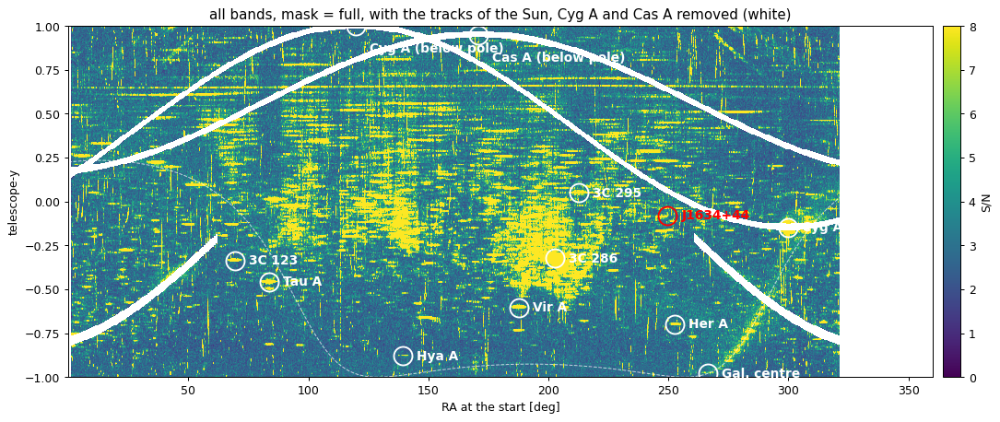

In [24]:
TRACKS = {"Sun": 0.03, "Cyg A": 0.02, "Cas A": 0.02}  # half-width in telescope-y
SUN_RA_WIDTH = 20.0  # degrees either side of the Sun's transit, masked at every telescope-y


def track(name, ra_axis):
    """Telescope-y of a source at each start time, and whether it is above the horizon."""
    sra, sdec = src_pos[name]
    h = np.radians(ra_axis - sra)
    d = np.radians(sdec)
    y = np.cos(LAT) * np.sin(d) - np.sin(LAT) * np.cos(d) * np.cos(h)
    up = np.sin(LAT) * np.sin(d) + np.cos(LAT) * np.cos(d) * np.cos(h) > 0
    return y, up


track_mask = np.zeros((g_el.size, g_ra.size), dtype=bool)
for name, half in TRACKS.items():
    y_t, up = track(name, g_ra)
    track_mask |= (np.abs(g_el[:, None] - y_t[None, :]) < half) & up[None, :]
track_mask |= (np.abs(((g_ra - src_pos["Sun"][0] + 180) % 360) - 180) < SUN_RA_WIDTH)[None, :]
print(f"fraction of the map masked: {track_mask.mean():.3f}")

fig, ax = plt.subplots(figsize=(16, 5.5))
im = plot_map(ax, np.where(track_mask, np.nan, gsnr["full"]["all"]),
              "all bands, mask = full, with the tracks of the Sun, Cyg A and Cas A removed (white)",
              vmin=0, vmax=8, ra_axis=g_ra, el_axis=g_el)
plt.colorbar(im, ax=ax, pad=0.01, label="S/N")

### The list

Set `CAND_GROUP = clean` to use the cleanest sub-band found above.

In [25]:
CAND_GROUP = "all"
# Candidates within this many degrees of RA of the transit of the Sun, Cas A or Cyg A
# are tagged at any telescope-y: their residuals spread over many rows
BRIGHT_WIDTH = {"Sun": 20.0, "Cas A": 12.0, "Cyg A": 12.0}

# Radio sources brighter than CAT_MIN_JY at 600 MHz.  A candidate within CAT_DY in
# telescope-y and CAT_DRA in RA of the transit of one of these is tagged with it.
CAT_MIN_JY, CAT_DY, CAT_DRA = 5.0, 0.01, 15.0
catalog = []
try:
    from ch_util import fluxcat

    for n in fluxcat.FluxCatalog.keys():
        try:
            s600 = float(fluxcat.FluxCatalog[n].predict_flux(600.0))
        except Exception:
            continue
        if np.isfinite(s600) and s600 >= CAT_MIN_JY:
            c_ = fluxcat.FluxCatalog[n]
            catalog.append((n, c_.ra % 360, c_.dec, s600, dec_to_el(c_.dec)))
except ImportError:
    print("ch_util.fluxcat is not available, so candidates are not matched to the catalogue")
print(f"{len(catalog)} catalogue sources above {CAT_MIN_JY:g} Jy at 600 MHz")


def find_peaks(img, valid, n, ra_axis, el_axis, sep_el=0.02, sep_ra=2.0):
    order = np.argsort(np.where(valid, img, -np.inf), axis=None)[::-1][: 2000 * n]
    found = []
    for flat in order:
        e, t = np.unravel_index(flat, img.shape)
        if any(abs(el_axis[e] - el_axis[e2]) < sep_el and abs(ra_axis[t] - ra_axis[t2]) < sep_ra for e2, t2 in found):
            continue
        found.append((e, t))
        if len(found) == n:
            break
    return found


def cat_match(r, y):
    """The brightest catalogue source transiting near (r, y), or None."""
    near = [c for c in catalog if abs(c[4] - y) < CAT_DY and abs(((r - c[1] + 180) % 360) - 180) < CAT_DRA]
    return max(near, key=lambda c: c[3]) if near else None


def near_tag(r, y):
    """J1634+44, or the transit (in RA only) of the Sun, Cas A or Cyg A."""
    if abs(y - el_j) < 0.03 and abs(r - ra_j) < 2:
        return "J1634+44"
    names = []
    for name, width in BRIGHT_WIDTH.items():
        sra = src_pos[name][0]
        if abs(((r - sra + 180) % 360) - 180) < width:
            names.append(name)
        elif name in BELOW_POLE and abs(((r - sra) % 360) - 180) < width:
            names.append(f"{name} (below pole)")
    return ", ".join(names)


def candidate_table(mm, name, found):
    """A table of candidates in the map of group `name`, indexed by their position in `found`."""
    rows = []
    for e, t in found:
        ix = gxi[mm][name][e, t]
        r, y = g_ra[t], g_el[e]
        row = {
            "S/N": float(gsnr[mm][name][e, t]),
            "telescope-y": y,
            "telescope-x": g_x[ix],
            "RA start": r,
            "UTC": ra_to_utc(r),
            "source RA": (r - g_ha[e, ix]) % 360,
            "source dec": g_dec[e, ix],
        }
        if name == "all":
            ec, tc = int(np.argmin(np.abs(el - y))), int(np.argmin(np.abs(ra - r)))
            row["amp [Jy]"] = float(best[mm]["amplitude"][ec, tc])
        row["y frac"] = frac6[t]
        row["sub-bands > 5"] = sum(int(gsnr[mm][n][e, t] > 5) for n in gsnr[mm] if n != "all")
        row["near transit of"] = near_tag(r, y)
        c_ = cat_match(r, y)
        row["catalogue source"] = c_[0] if c_ else ""
        row["S600 [Jy]"] = c_[3] if c_ else np.nan
        row["its transit - RA [deg]"] = ((c_[1] - r + 180) % 360) - 180 if c_ else np.nan
        rows.append(row)
    table = pd.DataFrame(rows)
    table.index.name = "#"
    return table.round({"S/N": 1, "telescope-y": 3, "telescope-x": 4, "RA start": 2, "source RA": 2,
                        "source dec": 1, "amp [Jy]": 2, "y frac": 2, "S600 [Jy]": 1, "its transit - RA [deg]": 1})


m = "full"
cmap_ = gsnr[m][CAND_GROUP]
valid = (cmap_ != 0) & ~track_mask
frac6 = np.sum(valid & (cmap_ > 6), axis=0) / np.maximum(valid.sum(axis=0), 1)
peaks = find_peaks(cmap_, valid, 100, g_ra, g_el)
table = candidate_table(m, CAND_GROUP, peaks)
untagged = table[(table["near transit of"] == "") & (table["catalogue source"] == "")]

print(f"{CAND_GROUP}, mask = {m}, without the bright-source tracks, the 20 brightest:")
display(table.head(20).fillna(""))
print("the 10 brightest not near a transit of the Sun, Cas A, Cyg A or a catalogue source, or J1634+44:")
display(untagged.head(10).fillna(""))

214 catalogue sources above 5 Jy at 600 MHz
all, mask = full, without the bright-source tracks, the 20 brightest:


,S/N,telescope-y,telescope-x,RA start,UTC,source RA,source dec,amp [Jy],y frac,sub-bands > 5,near transit of,catalogue source,S600 [Jy],its transit - RA [deg]
#,,,,,,,,,,,,,,
0,811.4,-0.020,0.0021,123.41,2022-02-28 05:41:09,123.60,48.2,1.65,0.09,9,Cyg A (below pole),3C_196,29.5,-0.0
1,505.8,-0.066,0.0064,139.86,2022-02-28 06:46:45,140.38,45.5,1.09,0.14,9,,3C_219,13.8,0.4
2,421.7,0.048,0.0021,212.58,2022-02-28 11:36:51,212.78,52.1,0.80,0.06,9,,3C_295,42.3,0.3
3,387.6,-0.324,0.0277,204.07,2022-02-28 11:02:53,205.91,30.4,3.58,0.17,8,,3C_286,21.8,-1.3
4,330.9,-0.301,0.0000,201.49,2022-02-28 10:52:37,201.49,31.8,0.65,0.13,9,,UGC_8782,7.1,6.6
5,330.6,-0.411,-0.0021,202.82,2022-02-28 10:57:55,202.69,25.0,0.75,0.20,9,,3C_287,9.6,-0.2
6,320.6,-0.324,0.0277,200.91,2022-02-28 10:50:18,202.75,30.4,2.72,0.13,9,,3C_286,21.8,1.9
7,308.2,-0.169,-0.0064,299.80,2022-02-28 17:24:46,299.32,39.6,1.12,0.03,4,Cyg A,NVSS_J202241+400832,9.2,5.9
8,305.4,0.010,-0.0149,85.95,2022-02-28 03:11:43,84.63,49.9,1.15,0.03,9,,3C_147,39.4,-0.3


the 10 brightest not near a transit of the Sun, Cas A, Cyg A or a catalogue source, or J1634+44:


,S/N,telescope-y,telescope-x,RA start,UTC,source RA,source dec,amp [Jy],y frac,sub-bands > 5,near transit of,catalogue source,S600 [Jy],its transit - RA [deg]
#,,,,,,,,,,,,,,
10,278.3,-0.036,0.0192,193.85,2022-02-28 10:22:08,195.47,47.2,1.28,0.19,9,,,,
13,221.6,-0.113,-0.0064,137.95,2022-02-28 06:39:08,137.45,42.8,0.45,0.09,8,,,,
15,160.8,-0.201,0.0021,137.08,2022-02-28 06:35:39,137.23,37.7,0.33,0.09,9,,,,
17,152.0,-0.201,-0.0149,139.11,2022-02-28 06:43:47,138.03,37.7,0.52,0.14,6,,,,
18,147.0,0.094,0.0085,53.68,2022-02-28 01:02:59,54.52,54.7,0.40,0.03,9,,,,
19,144.4,-0.377,0.0043,203.53,2022-02-28 11:00:44,203.80,27.2,0.33,0.17,8,,,,
20,141.2,-0.104,0.0000,60.41,2022-02-28 01:29:49,60.41,43.4,0.38,0.02,7,,,,
26,122.6,-0.120,0.0064,199.83,2022-02-28 10:46:00,200.33,42.4,0.25,0.16,9,,,,
30,114.2,-0.434,0.0021,211.88,2022-02-28 11:34:02,212.01,23.6,0.25,0.07,8,,,,


Pick a few of these and look at them more closely.  For each one:

- where it is in the whole day (red circle);
- a wider view, 30 degrees of RA, with the catalogue sources that transit there
  (white squares);
- the S/N along its row of telescope-y, with the transit of the matching
  catalogue source if there is one;
- the spectrum;
- the map around it in all bands and in each sub-band.

By default these are the three brightest in the list without a tag.  Change
`PICK` to look at others (the numbers are the positions in the list above),
for example a tagged one, to see what the residual of a catalogue source looks
like.

,S/N,telescope-y,telescope-x,RA start,UTC,source RA,source dec,amp [Jy],y frac,sub-bands > 5,near transit of,catalogue source,S600 [Jy],its transit - RA [deg]
#,,,,,,,,,,,,,,
10,278.3,-0.036,0.0192,193.85,2022-02-28 10:22:08,195.47,47.2,1.28,0.19,9,,,,


,all,A,B,TV1,TV2,TV3,5GDL,5GUL,LTE700,D
S/N in each sub-band,278.3,264.0,114.6,91.1,94.2,45.4,36.8,38.7,16.6,13.8


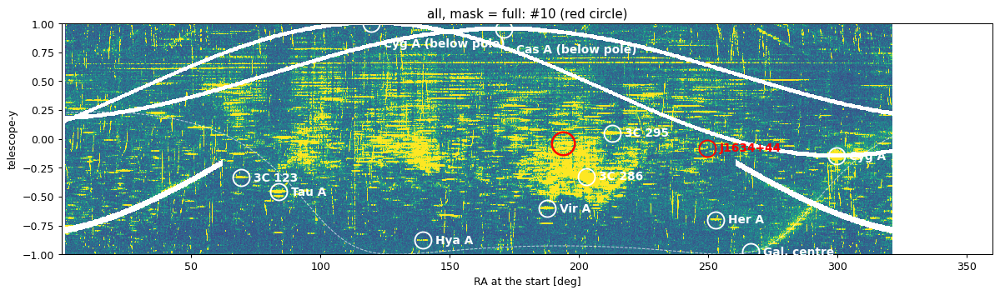

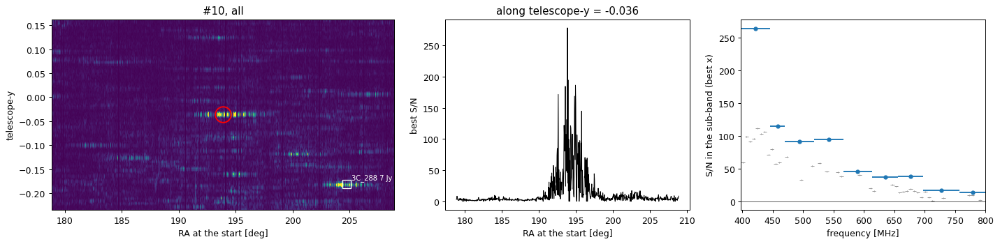

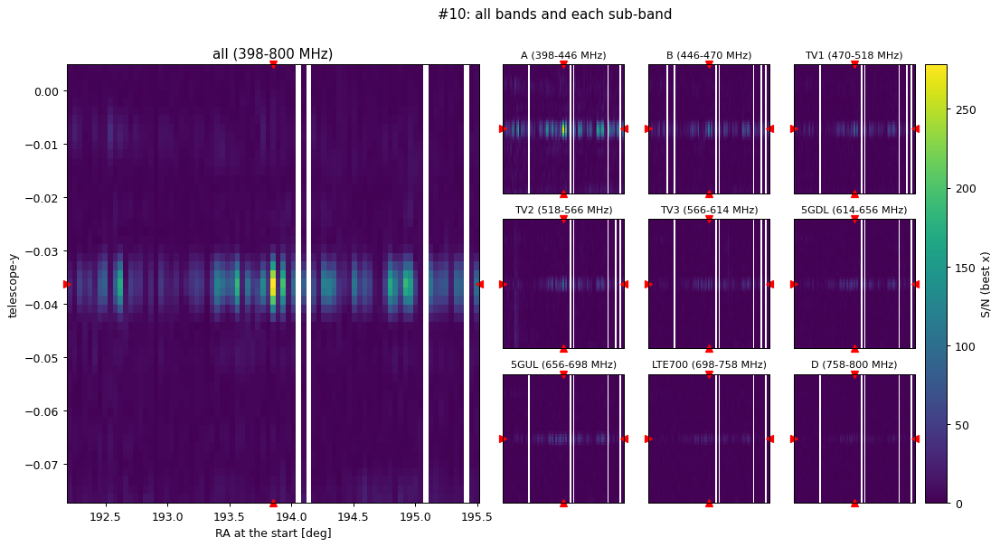

,S/N,telescope-y,telescope-x,RA start,UTC,source RA,source dec,amp [Jy],y frac,sub-bands > 5,near transit of,catalogue source,S600 [Jy],its transit - RA [deg]
#,,,,,,,,,,,,,,
13,221.6,-0.113,-0.0064,137.95,2022-02-28 06:39:08,137.45,42.8,0.45,0.09,8,,,,


,all,A,B,TV1,TV2,TV3,5GDL,5GUL,LTE700,D
S/N in each sub-band,221.6,183.0,73.6,62.0,68.9,48.0,48.7,60.5,28.9,1.8


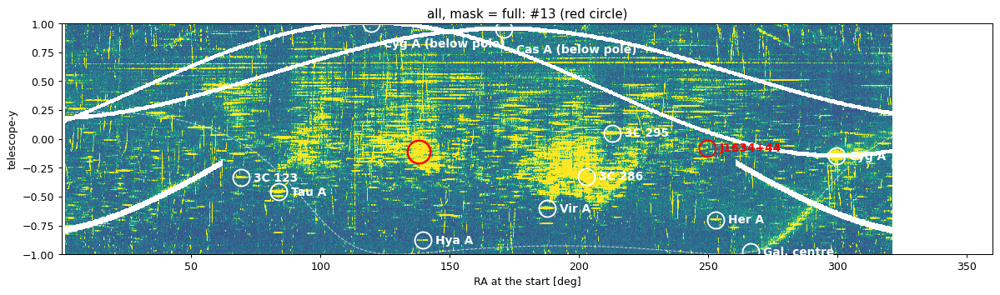

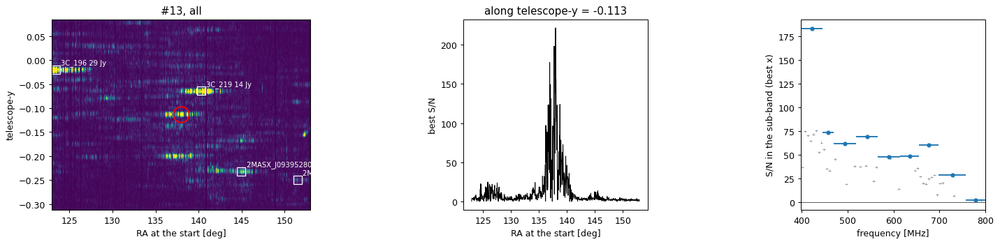

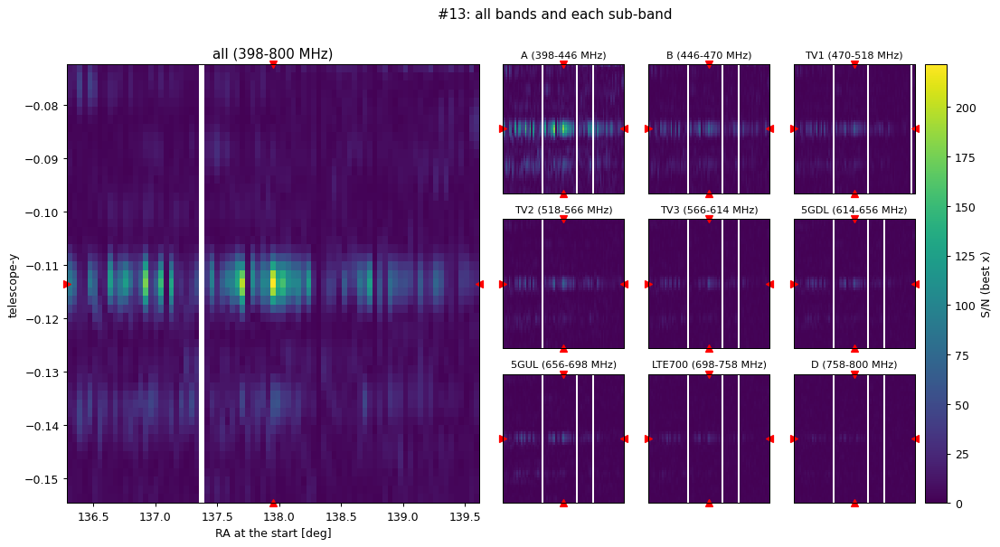

,S/N,telescope-y,telescope-x,RA start,UTC,source RA,source dec,amp [Jy],y frac,sub-bands > 5,near transit of,catalogue source,S600 [Jy],its transit - RA [deg]
#,,,,,,,,,,,,,,
15,160.8,-0.201,0.0021,137.08,2022-02-28 06:35:39,137.23,37.7,0.33,0.09,9,,,,


,all,A,B,TV1,TV2,TV3,5GDL,5GUL,LTE700,D
S/N in each sub-band,160.8,128.8,52.5,57.6,46.6,27.2,27.1,52.4,24.2,12.7


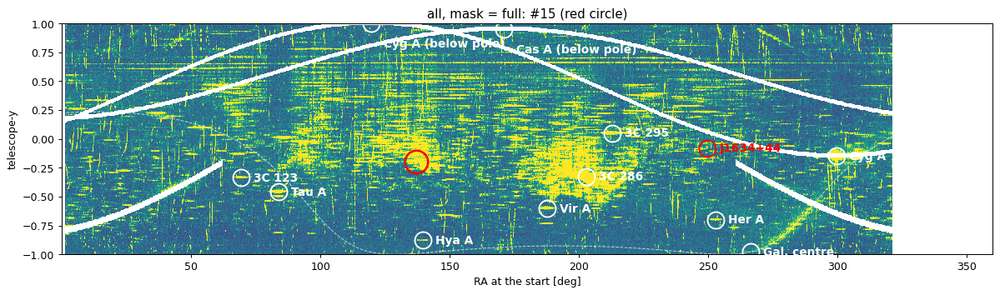

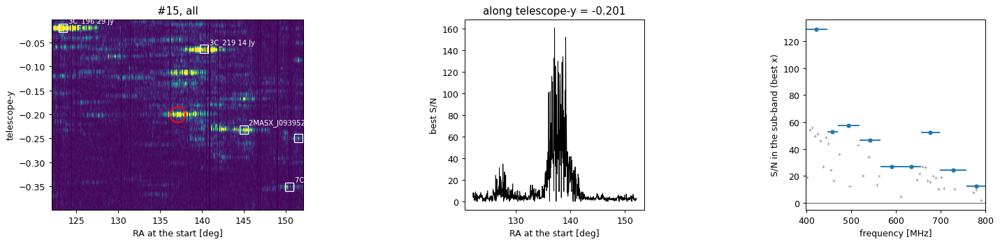

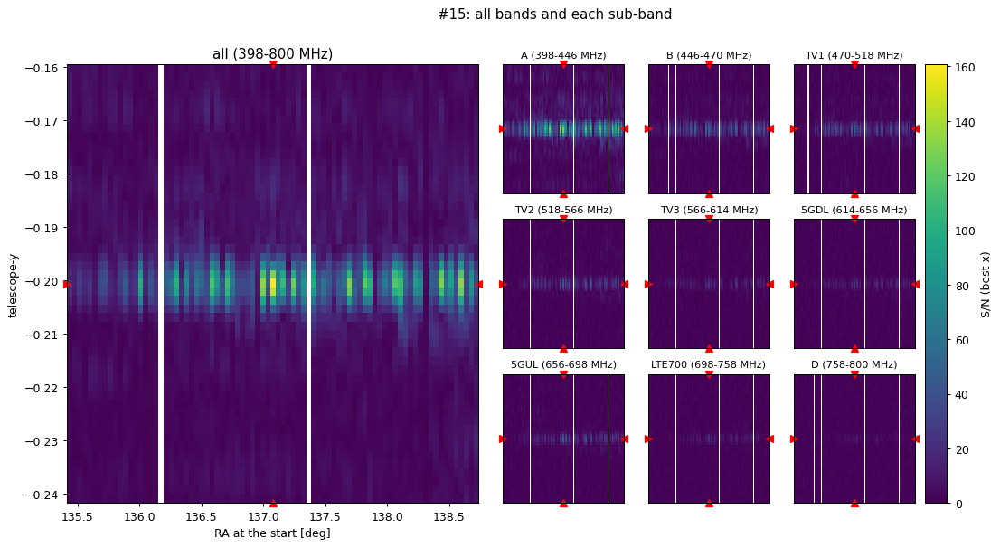

In [26]:
PICK = list(untagged.index[:3])


def show_candidate(k, mm="full", half_ra_deg=15.0, half_el=0.2):
    e, t = peaks[k]
    r0, y0 = g_ra[t], g_el[e]
    display(table.loc[[k]].fillna(""))
    display(pd.DataFrame({n: [float(gsnr[mm][n][e, t])] for n in gsnr[mm]}, index=["S/N in each sub-band"]).round(1))

    # Where it is in the whole day
    fig, ax = plt.subplots(figsize=(16, 4))
    plot_map(ax, np.where(track_mask, np.nan, cmap_), f"{CAND_GROUP}, mask = {mm}: #{k} (red circle)",
             vmin=0, vmax=8, ra_axis=g_ra, el_axis=g_el)
    ax.plot(r0, y0, "o", mfc="none", mec="r", ms=22, mew=2)

    # A wider view, with the catalogue sources that transit in it
    st = (g_ra > r0 - half_ra_deg) & (g_ra < r0 + half_ra_deg)
    se = (g_el > y0 - half_el) & (g_el < y0 + half_el)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={"width_ratios": [1.4, 1, 1]})
    plot_map(ax[0], cmap_[np.ix_(se, st)], f"#{k}, {CAND_GROUP}", vmin=0, vmax=max(8, gsnr[mm][CAND_GROUP][e, t] / 3),
             ra_axis=g_ra[st], el_axis=g_el[se], marks_on=False)
    ax[0].plot(r0, y0, "o", mfc="none", mec="r", ms=18, mew=1.5)
    for c_ in catalog:
        if abs(((c_[1] - r0 + 180) % 360) - 180) < half_ra_deg and abs(c_[4] - y0) < half_el:
            ax[0].plot(c_[1], c_[4], "s", mfc="none", mec="w", ms=10)
            ax[0].annotate(f"{c_[0]} {c_[3]:.0f} Jy", (c_[1], c_[4]), xytext=(6, 6), textcoords="offset points",
                           color="w", fontsize=8)
    ax[1].plot(g_ra[st], cmap_[e, st], "k-", lw=0.8)
    c_ = cat_match(r0, y0)
    if c_ is not None:
        ax[1].axvline(c_[1], color="C1", ls="--", label=f"transit of {c_[0]}")
        ax[1].legend(fontsize=8)
    ax[1].set(xlabel="RA at the start [deg]", ylabel="best S/N", title=f"along telescope-y = {y0:+.3f}")
    plot_spectrum(ax[2], e, t, mm, color="C0")
    plt.tight_layout()

    band_panels(e, t, mm, f"#{k}: all bands and each sub-band")
    plt.show()


for k in PICK:
    show_candidate(k)

When looking at these, the questions to ask are:

- Is it in all the sub-bands, or only some?  A signal confined to a few 6 MHz
  bands, or to the TV and LTE allocations, is almost certainly RFI.
- How many rows of telescope-y light up at the same time?  A real source is in
  a few rows (plus fainter copies through the north-south sidelobes if it is
  very bright); RFI often appears in all of them.
- Is a bright source transiting at the same time, or is it on the Galactic
  plane?
- Does it repeat at the same time or position on other days?

## Things to try next

- Go through the same steps for the other three days and compare.
- Make the list of candidates longer and sort them into groups by eye, then try
  to write simple rules (sub-band consistency, number of rows, near a
  bright source) that separate them.
- Compare what the RFI masks remove with what the sub-band test would catch, and
  which bands are worth keeping on each day.

A note on the bright sources and the scintillation patches: the runs used here have only the
receiver noise in the matched filter.  A first-order correction adds the
scintillation noise to the variance: at each sample it is predicted from the
unfiltered data and `kappa`.  It is in the runs ending in `_sky`, for mask = full
only (so far LSD 2418 and 3035):

    RUN_SUBDIR = "band_full/mask_{mask}/fir513_ew22_native_sky"
    MASKS = ["full"]

(the sections that compare the two masks then show only one).  It brings the S/N
near bright sources close to the noise and removes most, but not all, of the
scintillation patches.  I am working on fitting and subtracting the flicker directly, which
should do better.